# Aura — Calibration-Free EMG Challenge: Deep Analysis of the Training Data

**Companion to** `docs/Aura_EMG_Competition_Guide.md` · **Data version 2** (29 Oct 2026)

This notebook is a forensic tour of the 28 training sessions. The goal is not to win the
competition here, but to answer four practical questions before any modelling starts:

1. **What is actually in the files?** (sampling, labels, sessions, sensor columns)
2. **What will break a model?** (timestamp quirks, variable sample rates, DC offsets,
   label noise, leakage, session fingerprints)
3. **What signal distinguishes the six gestures?** (amplitude, channels, spectrum, IMU)
4. **How should the data be preprocessed and validated?** (a recipe that matches the
   test format and respects the competition's cross-person setting)

> **How to read this notebook:** every code cell is followed by an *Interpretation*
> block that states what the numbers mean and what to do about them. Figures are saved
> to `graphs/data_analysis/` **and displayed inline**. Paths resolve automatically on a
> local checkout or on Kaggle (see §0). A condensed write-up lives in
> `docs/data_analysis_report.md`.

## 0 · Setup

We use a light, consistent visual theme so that every figure is directly comparable.
The palette assigns one fixed colour to each gesture throughout the notebook.

**The notebook is platform-agnostic.** It finds the data automatically, so the same file
runs locally and on Kaggle without edits:

* **Outputs** go to `/kaggle/working` when that directory exists and is writable,
  otherwise to the repository root. Set `AURA_OUT_DIR` to force a location.
* **Training files** are searched in `data/raw/train`, `data/raw`, the current
  directory, and finally anywhere under `/kaggle/input`. Set `AURA_TRAIN_DIR` to force
  a location.
* **Test files** are read from a `test/` sibling of the training folder, from anywhere
  under `/kaggle/input`, or from `AURA_TEST_DIR`.
* The Parquet cache is **optional**: if `pyarrow` is missing or the cache cannot be
  written, the notebook simply continues in memory.

Every figure is both saved as a PNG and shown inline, so Kaggle's *Save & Run All*
produces the full visual report.

In [1]:
%matplotlib inline
from pathlib import Path
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm, LinearSegmentedColormap
import seaborn as sns
from scipy import signal
from scipy.stats import friedmanchisquare, wilcoxon, chi2_contingency, mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Image

warnings.filterwarnings("ignore", category=UserWarning)   # openpyxl style warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# ----------------------------------------------------------------------------- paths
def _looks_like_train_dir(path):
    """True if *path* is a directory containing at least one train_*.xlsx file."""
    path = Path(path)
    return path.is_dir() and any(path.glob("train_*.xlsx"))

def _find_train_dir():
    """Locate the training folder across local checkouts and Kaggle mounts."""
    # 1. Explicit override always wins.
    env = os.environ.get("AURA_TRAIN_DIR")
    if env and _looks_like_train_dir(env):
        return Path(env)

    # 2. Common local layouts (repo root or notebooks/ working directory).
    here = Path.cwd()
    repo = here.parent if here.name == "notebooks" else here
    for cand in (repo / "data" / "raw" / "train", repo / "data" / "raw",
                 here / "data" / "raw" / "train", here / "data" / "raw", here):
        if _looks_like_train_dir(cand):
            return cand

    # 3. Kaggle: the dataset is mounted read-only somewhere under /kaggle/input.
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        hits = sorted(kaggle_input.rglob("train_*.xlsx"))
        if hits:
            return hits[0].parent
    raise FileNotFoundError(
        "Could not find train_*.xlsx. Put the files in data/raw/train or set "
        "AURA_TRAIN_DIR to the folder that contains them.")

def _find_test_dir(train_dir):
    """Locate the test folder relative to the training folder or under /kaggle/input."""
    env = os.environ.get("AURA_TEST_DIR")
    if env and Path(env).is_dir():
        return Path(env)

    # Usually test/ is a sibling of train/ (local and Kaggle dataset layouts).
    for cand in (train_dir.parent / "test", train_dir / "test", train_dir.parent):
        if cand.is_dir() and any(cand.glob("test_*.xlsx")):
            return cand

    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        hits = sorted(kaggle_input.rglob("test_*.xlsx"))
        if hits:
            return hits[0].parent
    raise FileNotFoundError(
        "Could not find test_*.xlsx. Put the files in data/raw/test or set "
        "AURA_TEST_DIR to the folder that contains them.")

# Outputs: Kaggle working directory if available, else the repository root.
_env_out = os.environ.get("AURA_OUT_DIR")
if _env_out:
    OUT_DIR = Path(_env_out)
elif Path("/kaggle/working").is_dir() and os.access("/kaggle/working", os.W_OK):
    OUT_DIR = Path("/kaggle/working")
else:
    OUT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAW_TRAIN = _find_train_dir()
RAW_TEST = _find_test_dir(RAW_TRAIN)
INTERIM = OUT_DIR / "data" / "interim"
FIG_DIR = OUT_DIR / "graphs" / "data_analysis"
INTERIM.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"outputs   → {OUT_DIR}")
print(f"train     → {RAW_TRAIN}  ({len(list(RAW_TRAIN.glob('train_*.xlsx')))} files)")
print(f"test      → {RAW_TEST}  ({len(list(RAW_TEST.glob('test_*.xlsx')))} files)")
print(f"cache     → {INTERIM}")
print(f"figures   → {FIG_DIR}")

# ----------------------------------------------------------------------------- style
INK, MUTED, FAINT = "#111827", "#6b7280", "#e5e7eb"
CLASS_ORDER = ["rest", "fist", "open", "point", "pinch", "thumb-up"]
CLASS_COLORS = {
    "rest": "#94a3b8", "fist": "#e11d48", "open": "#0d9488",
    "point": "#f59e0b", "pinch": "#7c3aed", "thumb-up": "#ec4899",
}
SOURCE_COLORS = {"guided": "#0d9488", "optical": "#f59e0b", "none": "#cbd5e1"}
SIG = [f"ch{i}" for i in range(1, 9)] + ["ax", "ay", "az", "gx", "gy", "gz"]
EMG, IMU = [f"ch{i}" for i in range(1, 9)], ["ax", "ay", "az", "gx", "gy", "gz"]

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": "#d1d5db", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": FAINT, "grid.linewidth": 0.7,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 210,
    "savefig.bbox": "tight",
})

def savefig(fig, name):
    """Save a figure to graphs/data_analysis/ and show it inline."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, facecolor="white", bbox_inches="tight")
    plt.close(fig)
    try:
        shown = path.relative_to(OUT_DIR)
    except ValueError:
        shown = path
    print(f"saved → {shown}")
    display(Image(filename=str(path), width=900))

def panel_title(ax, text):
    ax.set_title(text, loc="left", fontsize=11, fontweight="bold", pad=8)

outputs   → /Users/khoatran3126/Documents/calibration-free-emg-challenge
train     → /Users/khoatran3126/Documents/calibration-free-emg-challenge/data/raw/train  (28 files)
test      → /Users/khoatran3126/Documents/calibration-free-emg-challenge/data/raw/test  (5 files)
cache     → /Users/khoatran3126/Documents/calibration-free-emg-challenge/data/interim
figures   → /Users/khoatran3126/Documents/calibration-free-emg-challenge/graphs/data_analysis


### Helper functions

Three helpers do the heavy lifting and are reused everywhere:

* `load_split()` reads the Excel files once and caches a Parquet copy
  (`data/interim/`). Parquet is ~10× faster and keeps re-runs cheap.
* `guided_segments()` cuts each session into the contiguous, human-labelled
  (`label_source == "guided"`) stretches described by the competition guide.
* `build_windows()` turns those stretches into **1.4-second windows** — the exact unit
  used by the test set — with a 50% stride.

The windowing logic is deliberately conservative:
* a window may **never cross a label change**;
* it may **never cross unlabelled (`none`) or camera-labelled (`optical`) rows**;
* it may **never cross a real recording gap** (> 0.30 s between consecutive rows).

In [2]:
def _file_key(path):
    """Sort train_2.xlsx numerically; tolerate unusual names without crashing."""
    tail = path.stem.split("_")[-1]
    return (0, int(tail), path.stem) if tail.isdigit() else (1, 0, path.stem)

def load_split(kind):
    """Read all Excel files for one split, using an optional Parquet cache."""
    cache = INTERIM / f"{kind}_all.parquet"
    if cache.exists():
        try:
            return pd.read_parquet(cache)
        except Exception as exc:
            print(f"parquet cache unreadable ({type(exc).__name__}); rebuilding from Excel")

    folder = RAW_TRAIN if kind == "train" else RAW_TEST
    frames = []
    for path in sorted(folder.glob("*.xlsx"), key=_file_key):
        d = pd.read_excel(path, sheet_name=0)
        d["file"] = path.stem
        d["row"] = np.arange(len(d))
        frames.append(d)
    df = pd.concat(frames, ignore_index=True)

    try:
        df.to_parquet(cache, index=False)
    except Exception as exc:
        # pyarrow/fastparquet may be unavailable or OUT_DIR read-only: keep going in memory.
        print(f"could not write parquet cache ({type(exc).__name__}); continuing in memory")
    return df

def guided_segments(session, gap_s=0.30):
    """Return guided rows with a segment id that breaks on label/source/gap changes."""
    g = session.loc[session.label_source == "guided"].sort_values("row").copy()
    new_segment = (
        (g.label != g.label.shift())        # label changes
        | (g.row.diff() != 1)               # unlabelled/optical rows in between
        | (g.t.diff() > gap_s)              # true recording dropout
    )
    g["segment"] = new_segment.cumsum()
    return g

def build_windows(train, win_s=1.4, stride_frac=0.5, gap_s=0.30):
    """Cut guided stretches into fixed-duration windows; returns window metadata."""
    rows = []
    for f, d in train.groupby("file", sort=False):
        rate = len(d) / (d.t.max() - d.t.min())          # rows per second, this session
        W = int(round(win_s * rate))                     # 1.4 s expressed in samples
        S = max(1, int(W * stride_frac))
        for _, seg in guided_segments(d, gap_s).groupby("segment"):
            n, label = len(seg), seg.label.iloc[0]
            for k in range(0, n - W + 1, S):
                rows.append(dict(
                    file=f, label=label, W=W, S=S, rate=rate,
                    start=int(seg.row.iloc[k]),
                    t_start=float(seg.t.iloc[k]),
                    segment=int(seg.segment.iloc[0]), seg_len=n,
                ))
    return pd.DataFrame(rows)

def window_features(x, rate):
    """Physically motivated, mostly scale-free features for one window.

    x : (n_samples, 14) array — 8 EMG channels followed by 6 IMU axes.
    """
    x = x.astype(float)
    xc = x - x.mean(axis=0)                  # mean-centre exactly like the test set
    rms = np.sqrt((xc ** 2).mean(axis=0))
    f = {}
    for i, c in enumerate(EMG):
        f[f"lrms_{c}"] = np.log(rms[i] + 1e-6)                                  # amplitude
        f[f"rel_{c}"] = np.log((rms[i] + 1e-6) / (rms[:8].mean() + 1e-6))       # relative to common mode
        f[f"zcr_{c}"] = np.mean(np.diff(np.signbit(xc[:, i])) != 0)             # zero-crossing rate
        f[f"wl_{c}"] = np.mean(np.abs(np.diff(xc[:, i]))) / (xc[:, i].std() + 1e-9)
        fr, p = signal.welch(xc[:, i], fs=rate, nperseg=min(128, len(xc)),
                             detrend="constant")
        tot = p.sum() + 1e-12
        f[f"cen_{c}"] = (fr * p).sum() / tot
        f[f"b_lo_{c}"] = p[(fr >= 1) & (fr < 15)].sum() / tot
        f[f"b_mid_{c}"] = p[(fr >= 15) & (fr < 40)].sum() / tot
        f[f"b_hi_{c}"] = p[fr >= 40].sum() / tot
    cc = np.nan_to_num(np.corrcoef(x[:, :8].T), nan=0.0)  # inter-channel coupling
    for i in range(8):
        for j in range(i + 1, 8):
            f[f"cor_{i}{j}"] = cc[i, j]
    for i, c in enumerate(IMU):
        f[f"imustd_{c}"] = np.std(xc[:, 8 + i])
    f["accmag_std"] = np.std(np.linalg.norm(xc[:, 8:11], axis=1))
    f["gyromag_std"] = np.std(np.linalg.norm(xc[:, 11:14], axis=1))
    return f

In [3]:
train = load_split("train")
test = load_split("test")

print(f"train: {train.shape[0]:,} rows × {train.shape[1]} cols, {train.file.nunique()} sessions")
print(f"test : {test.shape[0]:,} rows × {test.shape[1]} cols, {test.file.nunique()} files, "
      f"{test.action_id.nunique()} actions")
display(train.head(3))

train: 1,110,954 rows × 38 cols, 28 sessions
test : 111,620 rows × 19 cols, 5 files, 348 actions


,t,emg_new,imu_new,optical_new,ch1,ch2,ch3,ch4,ch5,ch6,...,thumb_curl,index_curl,middle_curl,ring_curl,pinky_curl,pinch,openness,thumb_up,file,row
0,0.015,1,1,0,-21825.13,35894.39,-23293.38,203811.41,-22848.67,10866.17,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train_1,0
1,0.015,1,0,0,-21915.79,35990.42,-23340.05,203957.32,-22911.97,10908.01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train_1,1
2,0.016,1,1,0,-21957.64,36030.11,-23371.70,204036.71,-22956.49,10915.52,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train_1,2


## 1 · Dataset at a glance

First, a session-level inventory. Each training file is one continuous recording of
roughly three minutes. The organisers describe these as "full recording sessions";
importantly, **there is no participant ID column**, so the file is the only grouping
unit we can defend for cross-validation.

In [4]:
session = (train.groupby("file")
                .agg(rows=("t", "size"), t0=("t", "min"), t1=("t", "max"),
                     guided=("label_source", lambda s: (s == "guided").mean())))
session["duration_s"] = session.t1 - session.t0
session["rate_hz"] = session.rows / session.duration_s

saved → graphs/data_analysis/01_dataset_overview.png


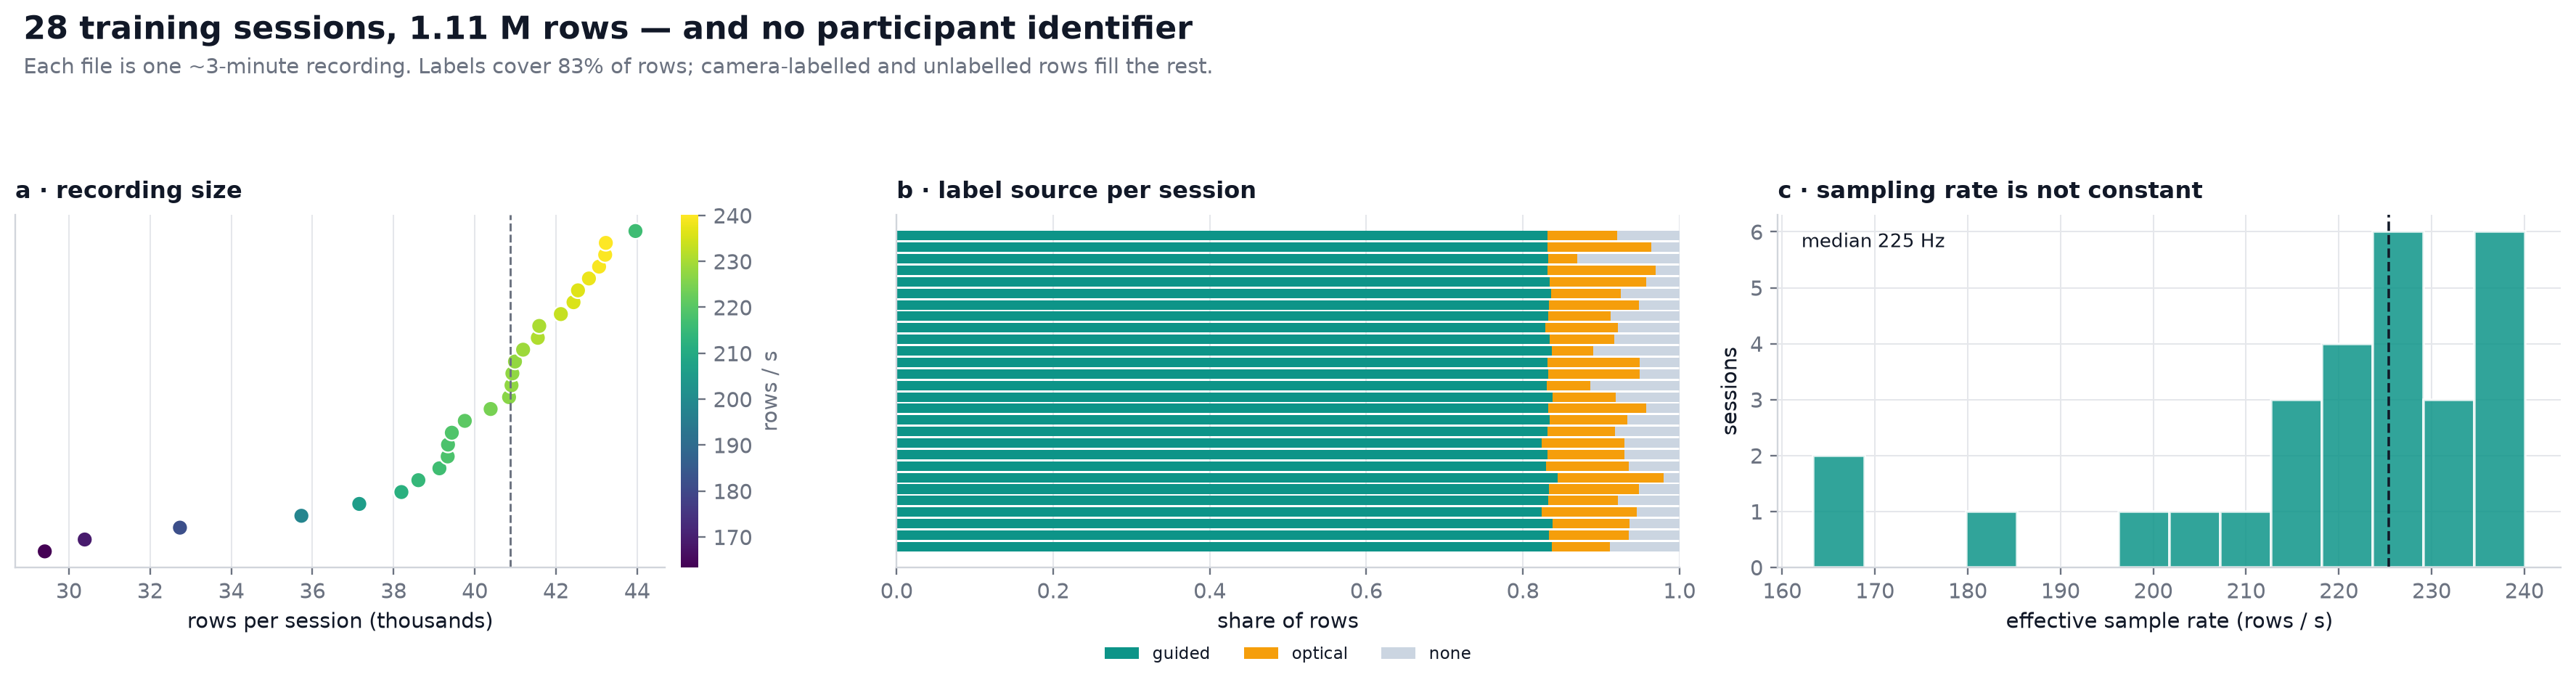

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) rows per session, coloured by effective sampling rate
s = session.sort_values("rows")
sc = axes[0].scatter(s.rows / 1000, np.arange(len(s)), c=s.rate_hz,
                     cmap="viridis", s=55, edgecolor="white", linewidth=0.8)
axes[0].axvline(s.rows.median() / 1000, color=MUTED, ls="--", lw=1)
axes[0].set_yticks([]); axes[0].set_xlabel("rows per session (thousands)")
panel_title(axes[0], "a · recording size")
cb = fig.colorbar(sc, ax=axes[0], pad=0.02)
cb.set_label("rows / s", color=MUTED)
cb.outline.set_visible(False)

# (b) composition of each session by label source
comp = pd.crosstab(train.file, train.label_source).reindex(columns=["guided", "optical", "none"])
comp_share = comp.div(comp.sum(axis=1), axis=0).loc[s.index]
bottom = np.zeros(len(comp_share))
for src in ["guided", "optical", "none"]:
    axes[1].barh(np.arange(len(comp_share)), comp_share[src], left=bottom,
                 color=SOURCE_COLORS[src], label=src, height=0.82)
    bottom += comp_share[src].values
axes[1].set_yticks([]); axes[1].set_xlim(0, 1)
axes[1].set_xlabel("share of rows")
axes[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8)
panel_title(axes[1], "b · label source per session")

# (c) distribution of effective sampling rates
axes[2].hist(session.rate_hz, bins=14, color="#0d9488", alpha=0.85,
             edgecolor="white", linewidth=1.2)
axes[2].axvline(session.rate_hz.median(), color=INK, ls="--", lw=1.2)
axes[2].text(0.03, 0.95, f"median {session.rate_hz.median():.0f} Hz",
             transform=axes[2].transAxes, va="top", fontsize=9, color=INK)
axes[2].set_xlabel("effective sample rate (rows / s)")
axes[2].set_ylabel("sessions")
panel_title(axes[2], "c · sampling rate is not constant")

fig.suptitle("28 training sessions, 1.11 M rows — and no participant identifier",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Each file is one ~3-minute recording. Labels cover 83% of rows; "
         "camera-labelled and unlabelled rows fill the rest.",
         fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "01_dataset_overview")

In [6]:
display(session[["rows", "duration_s", "rate_hz", "guided"]]
        .describe().round(2).T
        .rename(columns=lambda c: c.replace("_", " ").title()))

,Count,Mean,Std,Min,25%,50%,75%,Max
rows,28.0,39676.93,3693.96,29406.00,38998.50,40874.00,42198.00,43958.00
duration_s,28.0,180.96,4.40,179.96,180.02,180.06,180.15,203.39
rate_hz,28.0,219.27,19.95,163.38,215.71,225.37,231.47,240.09
guided,28.0,0.83,0.00,0.82,0.83,0.83,0.83,0.84


**Interpretation — §1**

* The dataset is **28 sessions × ~180 s**, totalling **1,110,954 rows**. One session
  (`train_16`) is longer (203 s) because it contains a 22 s dropout.
* The label-source mix is remarkably uniform: **83% guided**, **10% optical**,
  **7% unlabelled**. The consistency suggests a fixed recording protocol.
* Effective sampling rate is **not fixed** (163–240 rows/s). This is the first sign
  that *sample index is not time*: a "1.4 s window" is a different number of rows in
  every session.
* There is **no participant, subject, or session ID** beyond the filename. Cross-person
  validation therefore has to treat each file as one unit. Whether two files come from
  the same person is unknowable from the release alone.

## 2 · Sampling structure and the definition of a window

The test set is defined in **seconds** (1.4 s per action), but the training files are
exported in **rows**. Before anything else we need to know how rows map to time.

saved → graphs/data_analysis/02_sampling_structure.png


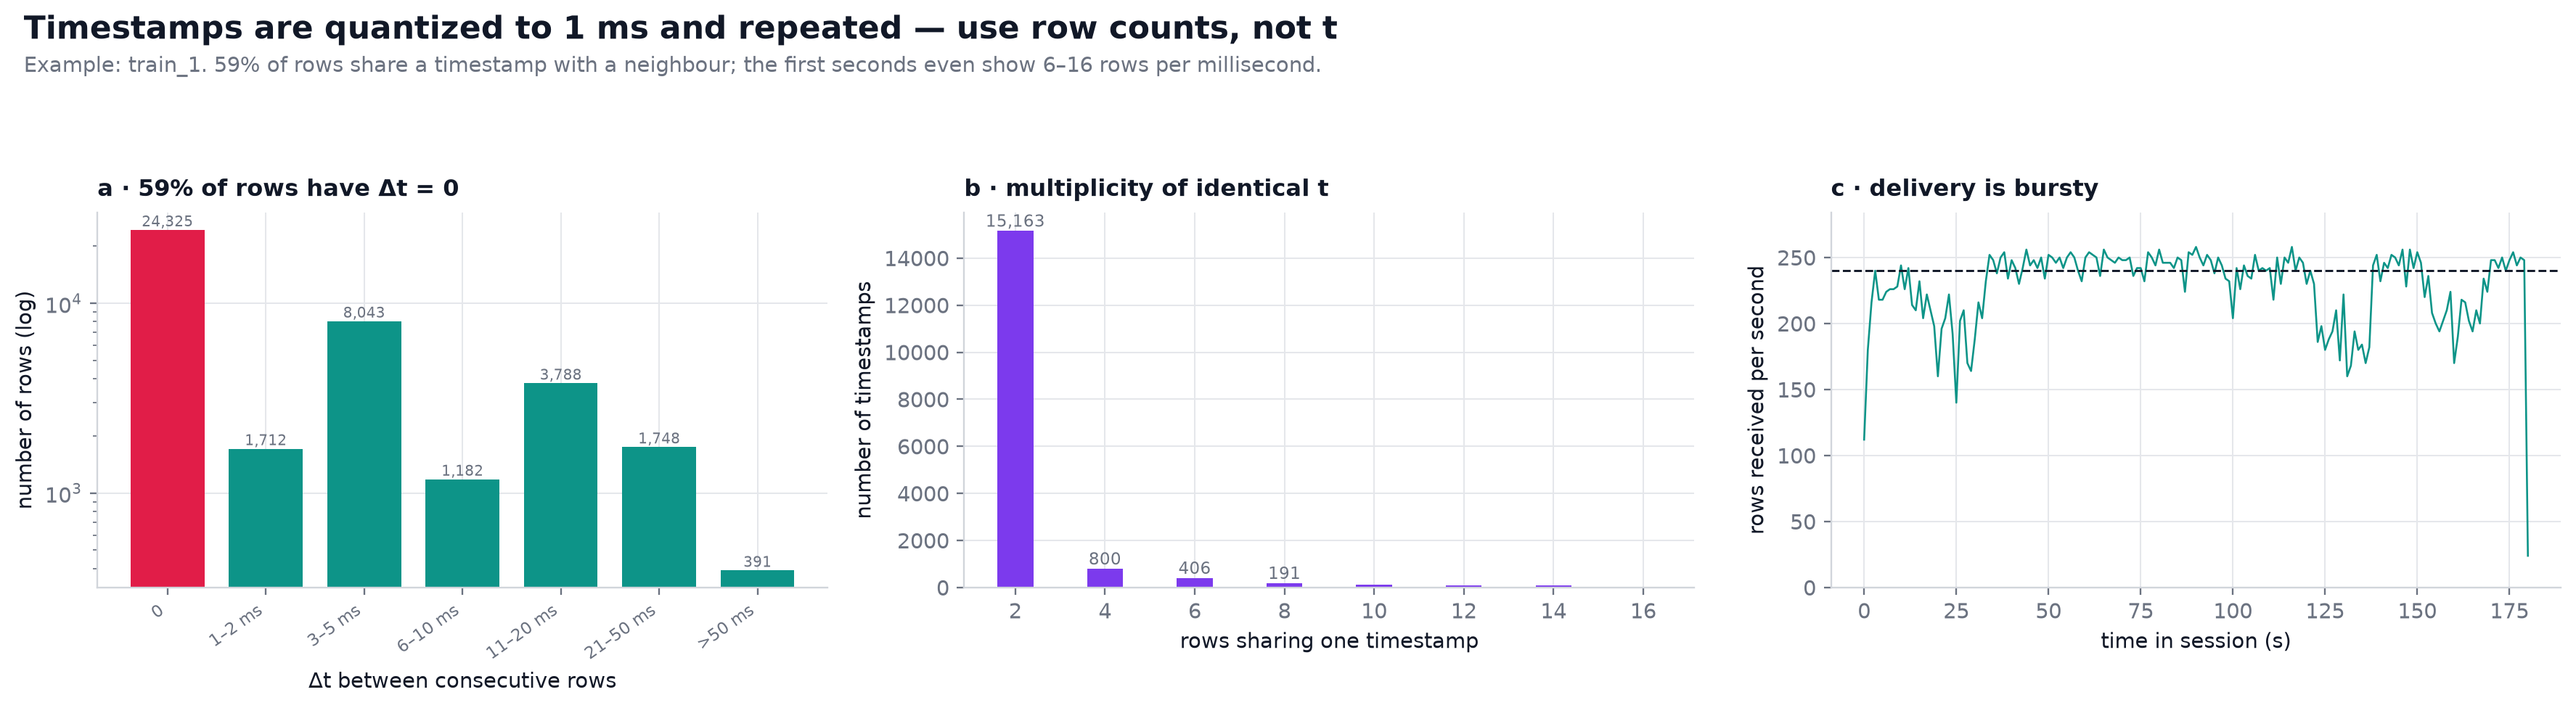

In [7]:
d1 = train[train.file == "train_1"].sort_values("row")
dt = d1.t.diff()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.7))

# (a) inter-row intervals: a huge spike at zero, then ~3-4 ms
dt_nonnull = dt.dropna()
cats = pd.cut(dt_nonnull, bins=[0, 1e-4, 0.0025, 0.0055, 0.0105, 0.021, 0.051, 1.0],
              labels=["0", "1–2 ms", "3–5 ms", "6–10 ms", "11–20 ms", "21–50 ms", ">50 ms"],
              right=False)
vc = cats.value_counts().reindex(cats.cat.categories)
axes[0].bar(range(len(vc)), vc.values,
            color=["#e11d48"] + ["#0d9488"] * (len(vc) - 1), width=0.75)
axes[0].set_xticks(range(len(vc)), vc.index, rotation=35, ha="right", fontsize=8)
axes[0].set_yscale("log")
axes[0].set_xlabel("Δt between consecutive rows")
axes[0].set_ylabel("number of rows (log)")
for i, v in enumerate(vc.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=7, color=MUTED)
panel_title(axes[0], "a · 59% of rows have Δt = 0")

# (b) how many rows share the same timestamp
mult = d1.t.value_counts().value_counts().sort_index()
axes[1].bar(mult.index, mult.values, color="#7c3aed", width=0.8)
axes[1].set_xlabel("rows sharing one timestamp")
axes[1].set_ylabel("number of timestamps")
for x, y in zip(mult.index[:4], mult.values[:4]):
    axes[1].text(x, y, f"{y:,}", ha="center", va="bottom", fontsize=8, color=MUTED)
panel_title(axes[1], "b · multiplicity of identical t")

# (c) burstiness: rows delivered per one-second bin
per_sec = d1.groupby(d1.t.astype(int)).size()
axes[2].plot(per_sec.index, per_sec.values, color="#0d9488", lw=0.9)
axes[2].axhline(per_sec.median(), color=INK, ls="--", lw=1)
axes[2].set_xlabel("time in session (s)")
axes[2].set_ylabel("rows received per second")
axes[2].set_ylim(0, per_sec.max() * 1.1)
panel_title(axes[2], "c · delivery is bursty")

fig.suptitle("Timestamps are quantized to 1 ms and repeated — use row counts, not t",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Example: train_1. 59% of rows share a timestamp with a neighbour; "
         "the first seconds even show 6–16 rows per millisecond.",
         fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "02_sampling_structure")

**Interpretation — §2.1**

* `t` is stored with **1 ms resolution**, and several consecutive rows carry the
  *same* value. These are **not duplicate records**: the EMG channels differ between
  them, while IMU values are held constant until `imu_new == 1`. The stream is
  multi-rate: EMG updates on essentially every row, IMU on ~36% of rows, optics on ~6%.
* A naive `t.diff()` therefore reports a median Δt of **0 s**, and any windowing by
  timestamp would silently drop most samples. **Window in row units, derived from each
  session's measured rate.**
* `emg_new` is constant (`1`) in both train and test and carries no information.
  `imu_new`/`optical_new` are arrival flags, not sensor values — do not feed them to a
  model.

### 2.1 · The 1.4-second window in samples

Because the rate varies, the same 1.4 s window is 229–336 rows in training and
**120–378 rows** in test. Any fixed-length model must resample.

saved → graphs/data_analysis/03_rate_variability.png


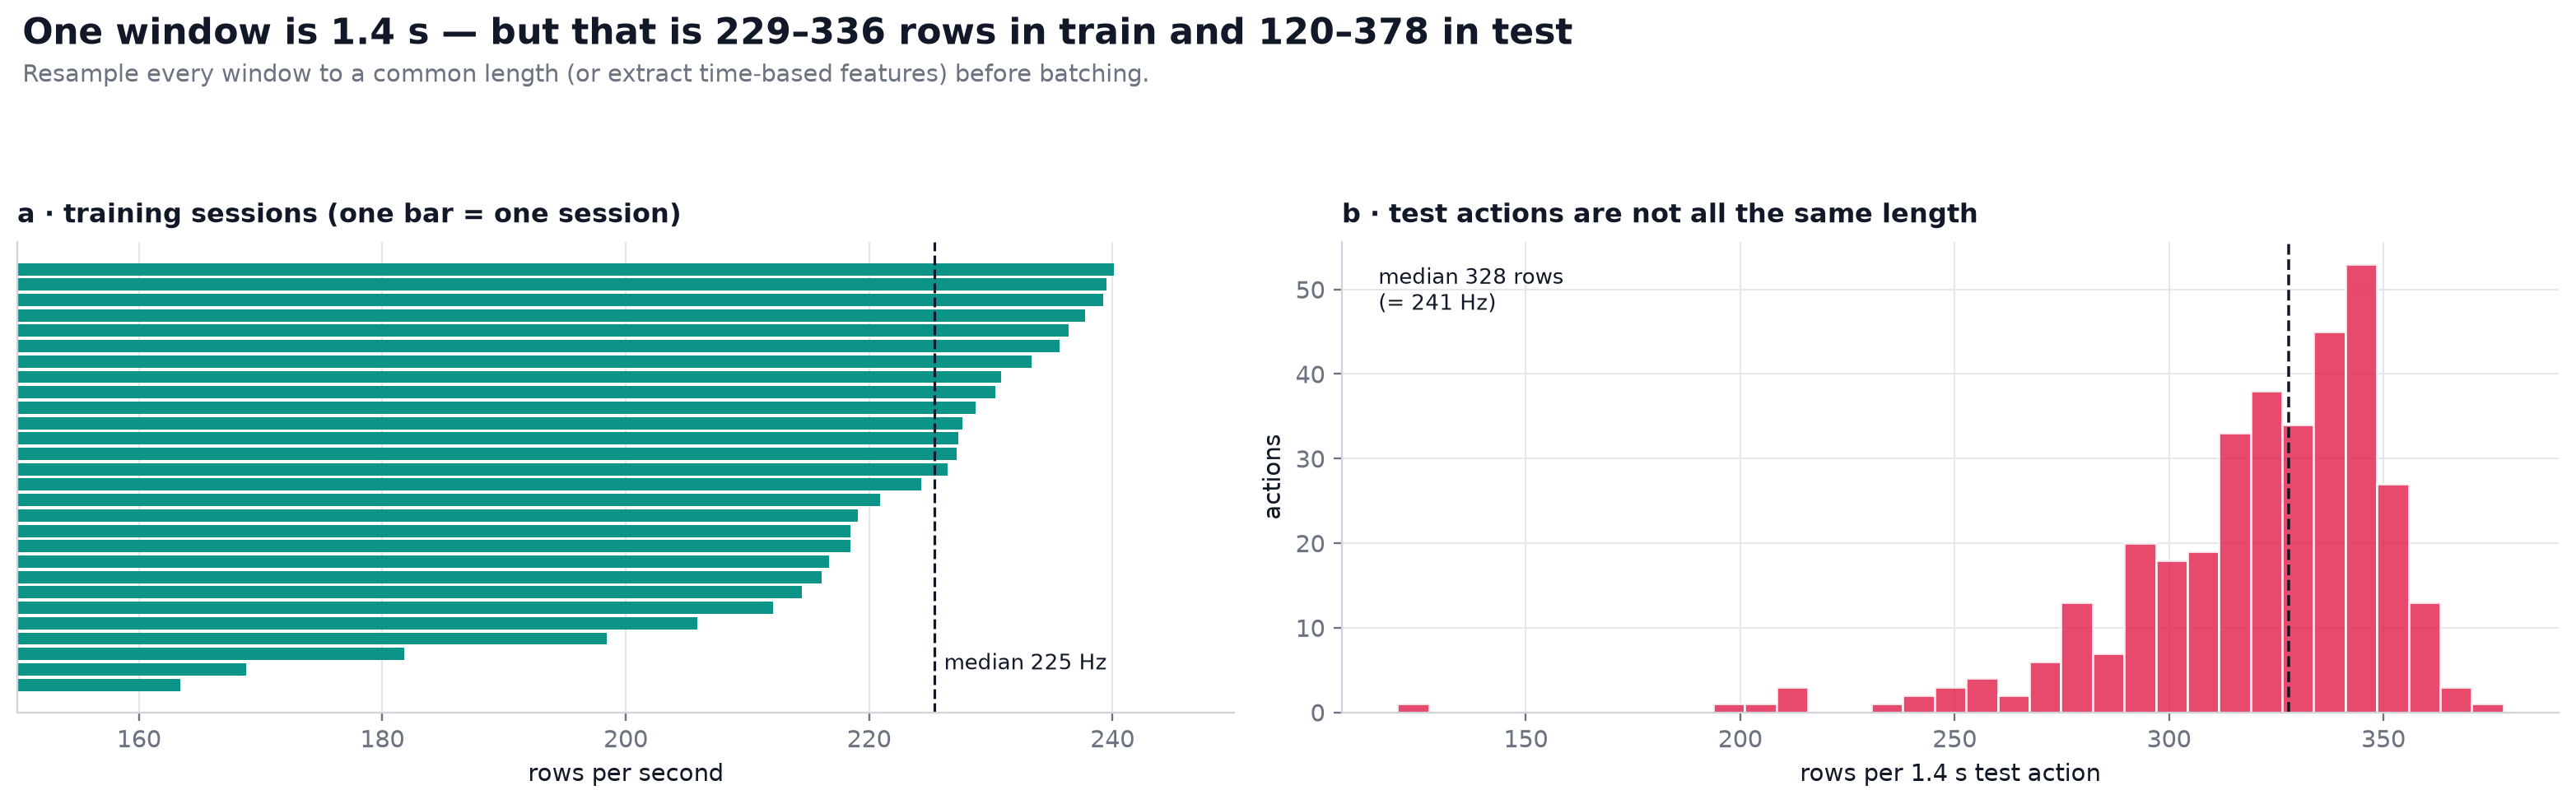

In [8]:
train_rate = (train.groupby("file")
                   .agg(rows=("t", "size"), t0=("t", "min"), t1=("t", "max")))
train_rate = train_rate.rows / (train_rate.t1 - train_rate.t0)

test_action = (test.groupby("action_id")
                    .agg(rows=("t", "size"), file=("file", "first"),
                         tmax=("t", "max")))
test_action["implied_hz"] = test_action.rows / test_action.tmax

fig, axes = plt.subplots(1, 2, figsize=(15, 4.7))

# (a) training rate per session
order = train_rate.sort_values().index
axes[0].barh(np.arange(len(order)), train_rate.loc[order].values,
             color="#0d9488", height=0.8)
axes[0].axvline(train_rate.median(), color=INK, ls="--", lw=1.1)
axes[0].set_yticks([]); axes[0].set_xlabel("rows per second")
axes[0].set_xlim(150, 250)
axes[0].annotate(f"median {train_rate.median():.0f} Hz", xy=(train_rate.median(), 1),
                 xytext=(4, 0), textcoords="offset points", fontsize=9)
panel_title(axes[0], "a · training sessions (one bar = one session)")

# (b) test actions
axes[1].hist(test_action.rows, bins=35, color="#e11d48", alpha=0.8,
             edgecolor="white", linewidth=1)
axes[1].axvline(test_action.rows.median(), color=INK, ls="--", lw=1.2)
axes[1].text(0.03, 0.95, f"median {test_action.rows.median():.0f} rows\n"
             f"(= {test_action.implied_hz.median():.0f} Hz)",
             transform=axes[1].transAxes, va="top", fontsize=9)
axes[1].set_xlabel("rows per 1.4 s test action")
axes[1].set_ylabel("actions")
panel_title(axes[1], "b · test actions are not all the same length")

fig.suptitle("One window is 1.4 s — but that is 229–336 rows in train and 120–378 in test",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Resample every window to a common length (or extract time-based "
         "features) before batching.", fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "03_rate_variability")

In [9]:
print(f"train rate  : min {train_rate.min():.1f} / median {train_rate.median():.1f} / "
      f"max {train_rate.max():.1f} rows per s")
print(f"test action : min {test_action.rows.min():.0f} / median {test_action.rows.median():.0f} / "
      f"max {test_action.rows.max():.0f} rows  "
      f"(implied {test_action.implied_hz.min():.0f}–{test_action.implied_hz.max():.0f} Hz)")
print(f"test actions per file: {test_action.groupby('file').size().to_dict()}")

train rate  : min 163.4 / median 225.4 / max 240.1 rows per s
test action : min 120 / median 328 / max 378 rows  (implied 90–280 Hz)
test actions per file: {'test_1': 60, 'test_2': 58, 'test_3': 110, 'test_4': 60, 'test_5': 60}


**Interpretation — §2.2**

* Training rates span **163–240 rows/s**; test actions imply **90–280 Hz** (median 241).
  The bulk of test actions sit near 220–260 Hz, but a tail is heavily downsampled or
  truncated (one action has only 120 rows).
* **Consequence 1 — resampling is mandatory.** Either resample every window to a fixed
  length (e.g. 256 samples) or use time-normalised features. Feeding raw row counts into
  a CNN will make the same gesture look longer or shorter depending on the participant.
* **Consequence 2 — padding/masking.** Actions as short as 120 rows cannot fill a
  336-row tensor. Use resampling rather than zero-padding so that short actions are not
  treated as "mostly silence".
* **Consequence 3 — avoid sample-rate-dependent features** (raw spectral bins). Use
  band ratios in Hz, spectral centroid in Hz, or resample first.

## 3 · Labels: composition, blocks, and a noisy camera

The competition guide is explicit: **only `label_source == "guided"` rows correspond to
test actions**. Everything else is a transition. Let us verify that advice with data.

3,125 windows · 229–336 rows each · 6 classes


saved → graphs/data_analysis/04_labels_and_timeline.png


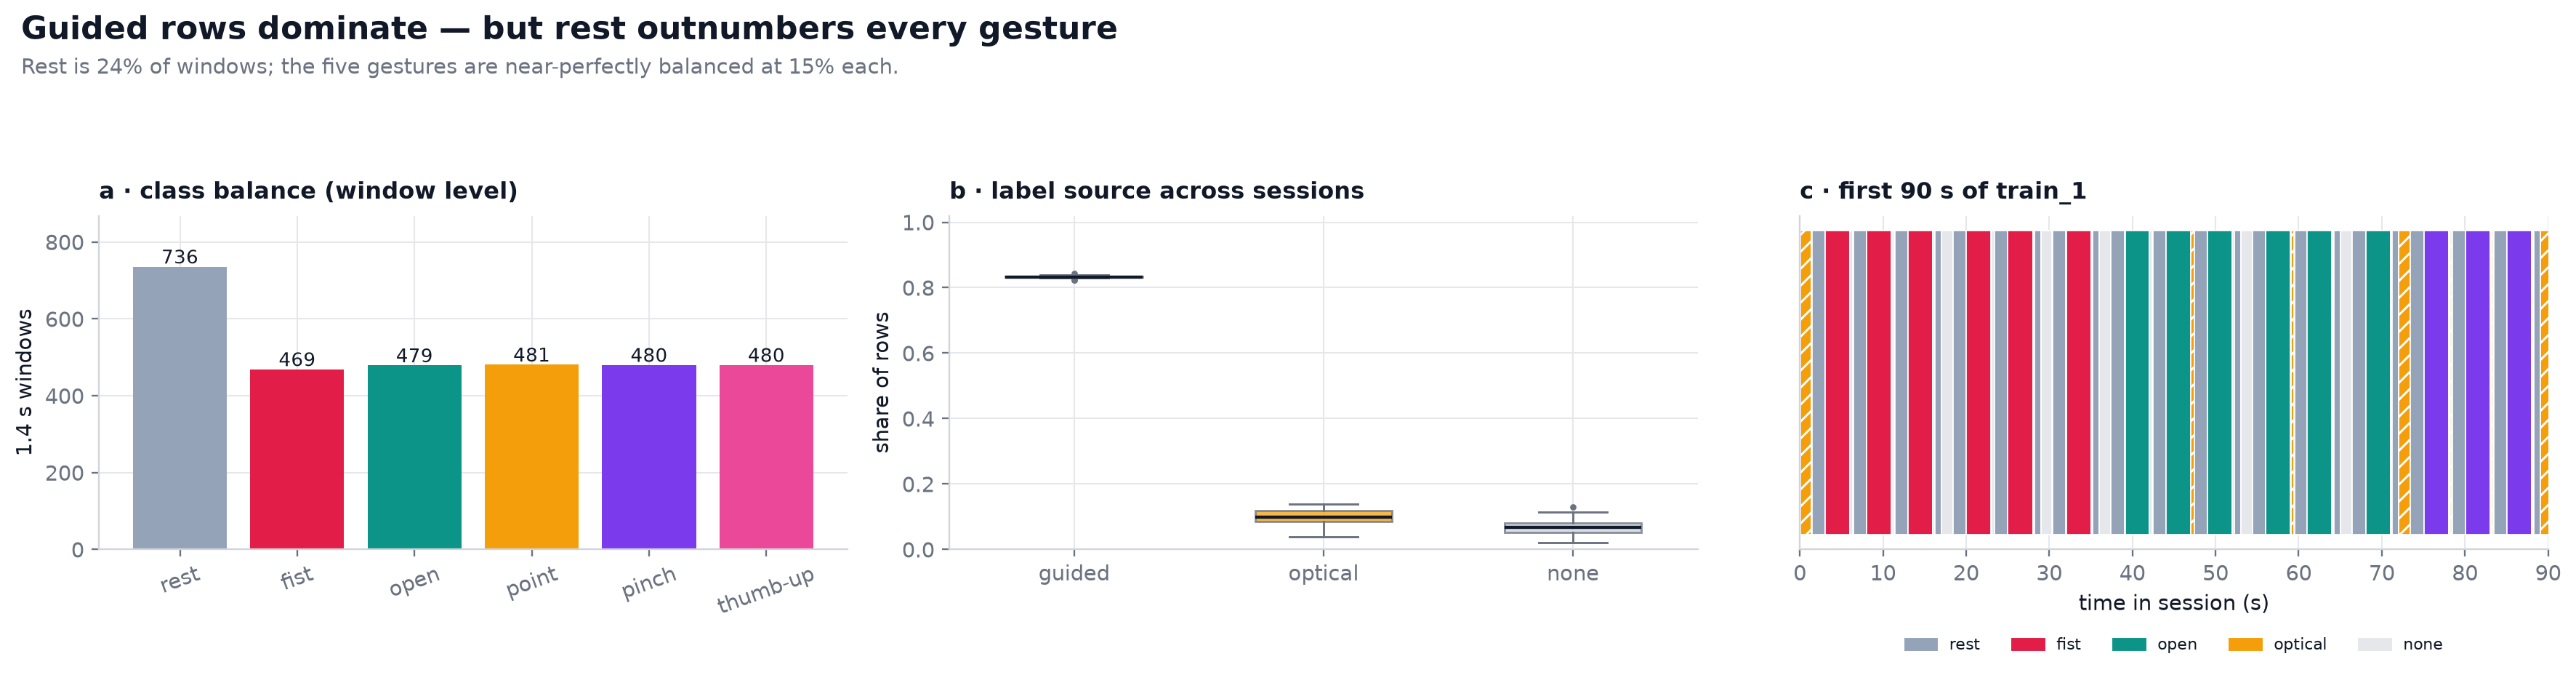

In [10]:
# Build the canonical windows now; they are used for the rest of the notebook.
windows = build_windows(train)
arrays = {f: d.sort_values("row")[SIG].to_numpy(float) for f, d in train.groupby("file")}
print(f"{len(windows):,} windows · {windows.W.min()}–{windows.W.max()} rows each "
      f"· {windows.label.nunique()} classes")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (a) window counts by class
counts = windows.label.value_counts().reindex(CLASS_ORDER)
axes[0].bar(CLASS_ORDER, counts.values, color=[CLASS_COLORS[c] for c in CLASS_ORDER])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 8, f"{v}", ha="center", fontsize=9, color=INK)
axes[0].set_ylabel("1.4 s windows")
axes[0].set_xticks(range(6), CLASS_ORDER, rotation=20)
axes[0].set_ylim(0, counts.max() * 1.18)
panel_title(axes[0], "a · class balance (window level)")

# (b) source composition, averaged over sessions
shares = (pd.crosstab(train.file, train.label_source)
            .reindex(columns=["guided", "optical", "none"])
            .div(train.groupby("file").size(), axis=0))
axes[1].boxplot([shares[c] for c in ["guided", "optical", "none"]],
                patch_artist=True, widths=0.55,
                medianprops=dict(color=INK, lw=1.5),
                boxprops=dict(facecolor="white", edgecolor=MUTED),
                whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED,
                                markeredgecolor="none"))
for patch, c in zip(axes[1].patches, ["guided", "optical", "none"]):
    patch.set_facecolor(SOURCE_COLORS[c]); patch.set_alpha(0.75)
axes[1].set_xticks([1, 2, 3], ["guided", "optical", "none"])
axes[1].set_ylabel("share of rows")
axes[1].set_ylim(0, 1.02)
panel_title(axes[1], "b · label source across sessions")

# (c) timeline of one session
d = train[train.file == "train_1"].sort_values("row")
state = d.label.fillna("unlabelled").astype(str) + "|" + d.label_source
run = (state != state.shift()).cumsum()
runs = d.groupby(run).agg(label=("label", "first"), source=("label_source", "first"),
                          t0=("t", "first"), t1=("t", "last")).reset_index(drop=True)
for i, r in runs.iterrows():
    if r.source == "guided":
        color, hatch = CLASS_COLORS[r.label], None
    elif r.source == "optical":
        color, hatch = "#f59e0b", "///"
    else:
        color, hatch = "#e5e7eb", None
    axes[2].broken_barh([(r.t0, max(r.t1 - r.t0, 0.02))], (0, 1),
                        facecolors=color, edgecolor="white", linewidth=0.6, hatch=hatch)
axes[2].set_xlim(0, 90); axes[2].set_yticks([])
axes[2].set_xlabel("time in session (s)")
handles = [plt.Rectangle((0, 0), 1, 1, color=CLASS_COLORS[c]) for c in ["rest", "fist", "open"]]
handles += [plt.Rectangle((0, 0), 1, 1, color="#f59e0b", hatch="///"),
            plt.Rectangle((0, 0), 1, 1, color="#e5e7eb")]
axes[2].legend(handles, ["rest", "fist", "open", "optical", "none"],
               ncol=5, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.22))
panel_title(axes[2], "c · first 90 s of train_1")

fig.suptitle("Guided rows dominate — but rest outnumbers every gesture",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Rest is 24% of windows; the five gestures are near-perfectly "
         "balanced at 15% each.", fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "04_labels_and_timeline")

In [11]:
print("window class counts:")
print(counts.to_string())
print(f"\nrest share of guided windows: {counts['rest'] / counts.sum():.1%}")

window class counts:
label
rest        736
fist        469
open        479
point       481
pinch       480
thumb-up    480

rest share of guided windows: 23.6%


**Interpretation — §3.1**

* **Rest is over-represented**: 736 of 3,125 windows (23.6%), versus ~15% for each
  gesture. Macro-F1 gives every class equal weight, so a model that ignores rare classes
  is directly punished. Use class-balanced loss or per-class thresholds.
* The label timeline shows a clean block design: human-guided stretches separated by
  short unlabelled or camera-labelled periods. There is no label "bleed" across rows.
* Because only guided rows match the test actions, **~17% of the rows are not usable
  for supervised training** as-is. That is by design, not an error.

### 3.1 · What a "block" looks like

The guided stretches are not all the same length. Gestures are held for ~3 s, while rest
is chopped into many shorter pieces. This matters because a 1.4 s window cannot be cut
from a 0.9 s block.

saved → graphs/data_analysis/05_block_structure.png


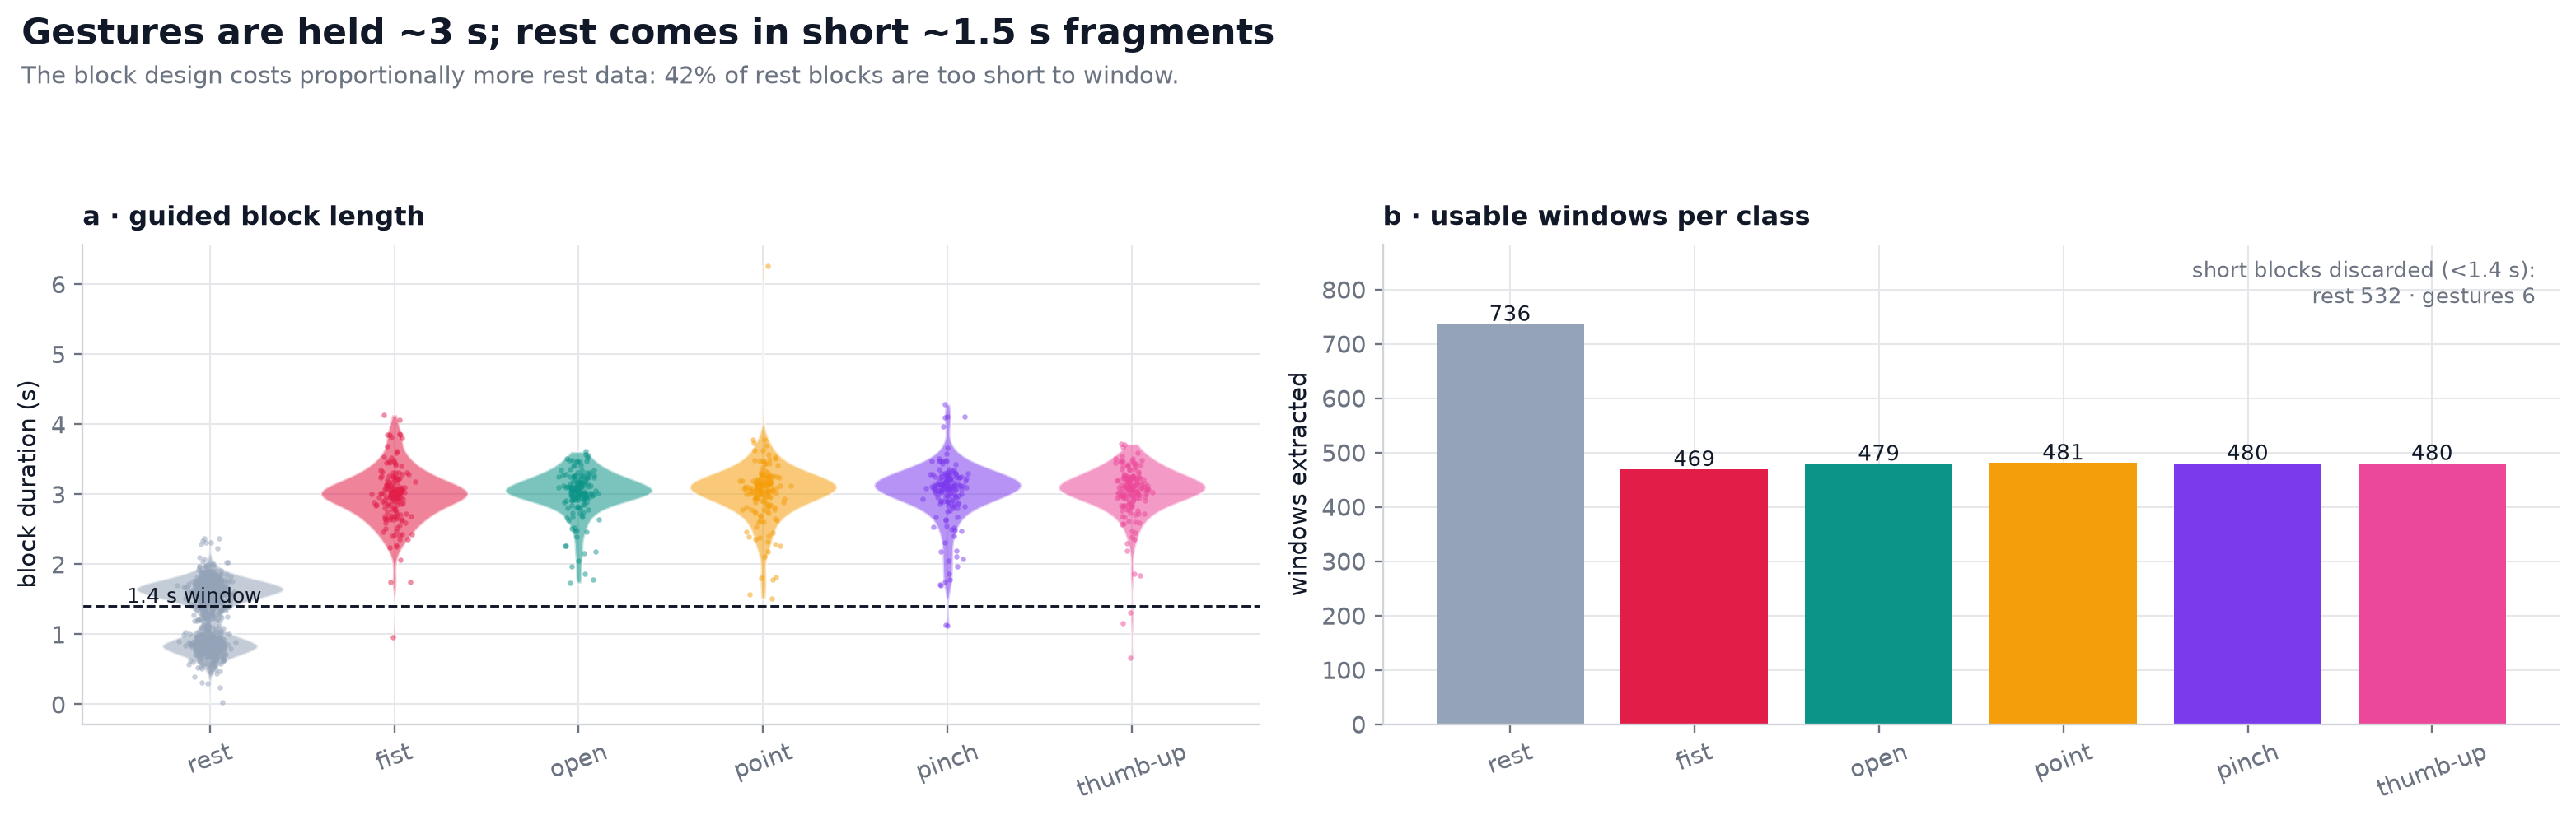

In [12]:
blocks = []
for f, d in train.groupby("file"):
    rate = len(d) / (d.t.max() - d.t.min())
    W = int(round(1.4 * rate))
    for _, seg in guided_segments(d).groupby("segment"):
        n = len(seg)
        nwin = (n - W) // max(1, W // 2) + 1 if n >= W else 0
        blocks.append(dict(file=f, label=seg.label.iloc[0], rows=n, W=W,
                           seconds=n / rate, nwin=nwin))
blocks = pd.DataFrame(blocks)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

# (a) block duration by class
data = [blocks.loc[blocks.label == c, "seconds"].values for c in CLASS_ORDER]
parts = axes[0].violinplot(data, showextrema=False, widths=0.8)
for pc, c in zip(parts["bodies"], CLASS_ORDER):
    pc.set_facecolor(CLASS_COLORS[c]); pc.set_alpha(0.55); pc.set_edgecolor("white")
for i, c in enumerate(CLASS_ORDER):
    y = blocks.loc[blocks.label == c, "seconds"]
    axes[0].scatter(np.random.default_rng(i).normal(i + 1, 0.045, len(y)), y,
                    s=5, color=CLASS_COLORS[c], alpha=0.5, linewidth=0)
axes[0].axhline(1.4, color=INK, ls="--", lw=1)
axes[0].text(0.55, 1.45, "1.4 s window", fontsize=8.5, color=INK)
axes[0].set_xticks(range(1, 7), CLASS_ORDER, rotation=20)
axes[0].set_ylabel("block duration (s)")
panel_title(axes[0], "a · guided block length")

# (b) windows obtained per class, with dropped short blocks
wins_per_class = blocks.groupby("label").nwin.sum().reindex(CLASS_ORDER)
short = blocks.assign(short=blocks.rows < blocks.W).groupby("label")["short"].sum().reindex(CLASS_ORDER)
axes[1].bar(CLASS_ORDER, wins_per_class.values, color=[CLASS_COLORS[c] for c in CLASS_ORDER])
for i, c in enumerate(CLASS_ORDER):
    axes[1].text(i, wins_per_class[c] + 6, f"{wins_per_class[c]}", ha="center", fontsize=9)
axes[1].set_ylabel("windows extracted")
axes[1].set_xticks(range(6), CLASS_ORDER, rotation=20)
axes[1].set_ylim(0, wins_per_class.max() * 1.2)
axes[1].text(0.98, 0.97,
             f"short blocks discarded (<1.4 s):\nrest {short['rest']:.0f} · "
             f"gestures {short.drop('rest').sum():.0f}",
             transform=axes[1].transAxes, fontsize=9, va="top", ha="right", color=MUTED)
panel_title(axes[1], "b · usable windows per class")

fig.suptitle("Gestures are held ~3 s; rest comes in short ~1.5 s fragments",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "The block design costs proportionally more rest data: 42% of rest "
         "blocks are too short to window.", fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "05_block_structure")

In [13]:
print(blocks.groupby("label").agg(blocks=("rows", "size"), median_s=("seconds", "median"),
                                  windows=("nwin", "sum")).round(2).to_string())

          blocks  median_s  windows
label                              
fist         168      3.00      469
open         168      3.05      479
pinch        170      3.11      480
point        168      3.08      481
rest        1260      1.53      736
thumb-up     169      3.09      480


**Interpretation — §3.2**

* Gesture blocks are **~3.0 s**, so a 50%-overlap scheme yields ~3 windows per block.
  Rest blocks are **~1.5 s** on median and 532 of 1,260 are shorter than 1.4 s: they are
  **discarded**. This is why rest contributes only ~1 window per block despite having the
  most rows.
* The 78% row coverage (721,805 of 925,184 guided rows) is the price of strict
  boundary-respecting windows. Overlap recovers almost all of it; the remaining loss is
  short rest fragments and edge trim.
* **Do not merge adjacent rest blocks across unlabelled gaps.** Those gaps are real
  transitions and may contain motion; including them would teach the model that
  movement = rest.

### 3.2 · The camera/optical labels are not trustworthy

The `optical_*` columns come from hand tracking. The guide warns that camera columns are
absent from the test set — but the training labels themselves also sometimes come from
the camera (`label_source == "optical"`). Is that a second opinion, or noise?

saved → graphs/data_analysis/06_camera_labels.png


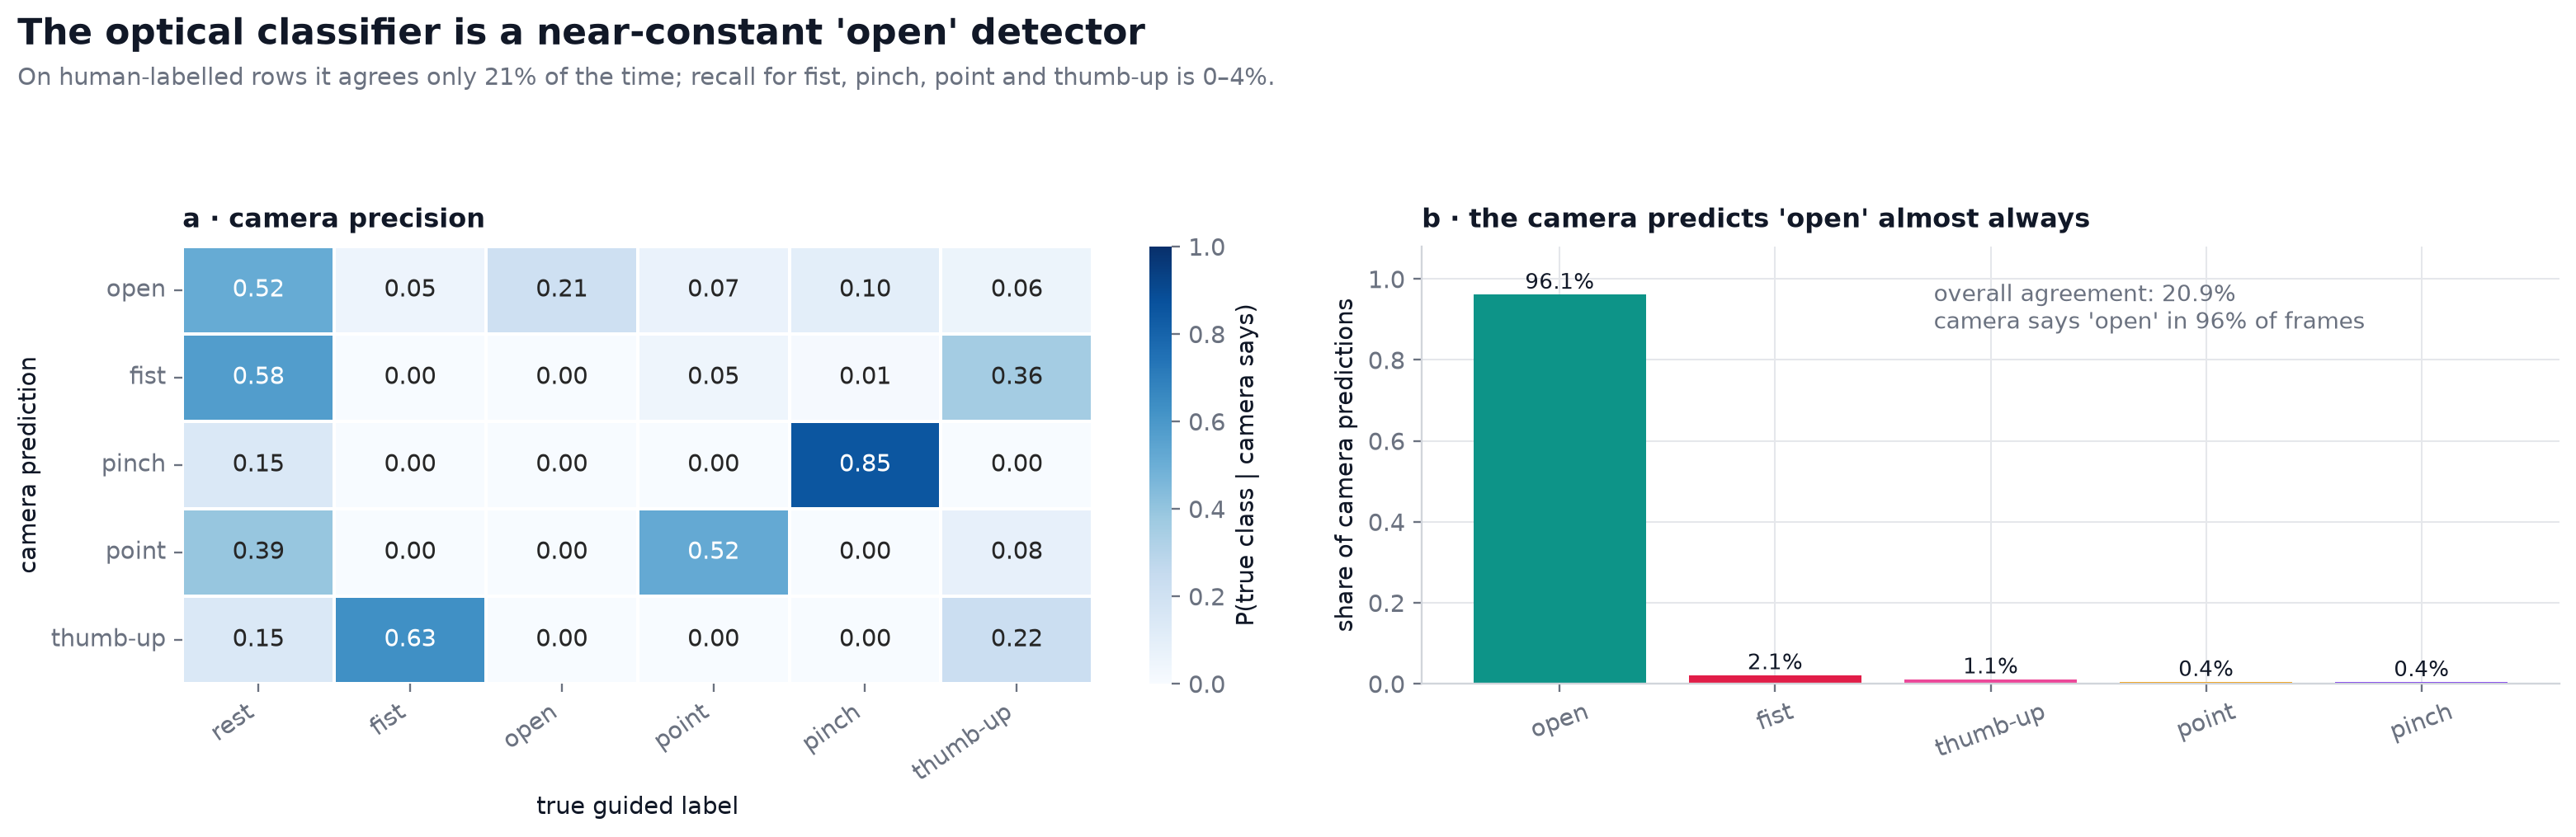

In [14]:
g = train[(train.label_source == "guided") & train.optical_class.notna()]
prec = pd.crosstab(g.optical_class, g.label, normalize="index").reindex(
    index=["open", "fist", "pinch", "point", "thumb-up"], columns=CLASS_ORDER, fill_value=0)
pred_share = g.optical_class.value_counts(normalize=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.9))
sns.heatmap(prec, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            linewidths=1.2, linecolor="white", cbar_kws={"label": "P(true class | camera says)"},
            ax=axes[0])
axes[0].set_xlabel("true guided label")
axes[0].set_ylabel("camera prediction")
axes[0].set_xticklabels(CLASS_ORDER, rotation=35, ha="right")
axes[0].set_yticklabels(prec.index, rotation=0)
panel_title(axes[0], "a · camera precision")

axes[1].bar(pred_share.index, pred_share.values,
            color=[CLASS_COLORS.get(c, "#94a3b8") for c in pred_share.index])
for i, (c, v) in enumerate(pred_share.items()):
    axes[1].text(i, v + 0.015, f"{v:.1%}", ha="center", fontsize=9)
axes[1].set_ylim(0, 1.08)
axes[1].set_ylabel("share of camera predictions")
axes[1].set_xticks(range(len(pred_share)), pred_share.index, rotation=20)
axes[1].text(0.45, 0.92, f"overall agreement: {(g.label == g.optical_class).mean():.1%}\n"
             f"camera says 'open' in {pred_share.get('open', 0):.0%} of frames",
             transform=axes[1].transAxes, va="top", fontsize=9.5, color=MUTED)
panel_title(axes[1], "b · the camera predicts 'open' almost always")

fig.suptitle("The optical classifier is a near-constant 'open' detector",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "On human-labelled rows it agrees only 21% of the time; recall for "
         "fist, pinch, point and thumb-up is 0–4%.", fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "06_camera_labels")

In [15]:
cam = (g.assign(ok=g.label == g.optical_class)
         .groupby("label").ok.agg(["mean", "size"]).reindex(CLASS_ORDER))
print("camera agreement with human labels:")
print(cam.round(3).to_string())
print("\noptical-sourced rows by label:")
print(train.loc[train.label_source == "optical", "label"].value_counts().to_string())

camera agreement with human labels:
           mean    size
label                  
rest      0.000  244950
fist      0.001   26900
open      1.000   96642
point     0.032   32182
pinch     0.031   47638
thumb-up  0.037   31376

optical-sourced rows by label:
label
open        105824
fist          2422
thumb-up       620
pinch          508
point          230


**Interpretation — §3.3**

* The camera is essentially an **"open hand" detector**: 96% of its predictions are
  `open`. It achieves 100% recall on `open` but only 0–4% recall on everything else.
* `label_source == "optical"` therefore injects **~106k confidently wrong-ish labels**,
  overwhelmingly `open`, into an otherwise balanced problem. Including them would teach
  the model that nearly every pose is `open`.
* **Recommendation:** train on `guided` rows only, exactly as the guide says. If you want
  extra data, you could treat optical rows as *unlabelled* for semi-supervised learning,
  but not as ground truth.
* The `handedness` column is also noisy: 97% `Right`, with brief `Left`/`unknown`
  flickers mid-session. It is metadata, not a reliable covariate.

## 4 · Signal quality: offsets, gain, saturation, dropouts, spectrum

EMG is recorded as raw ADC counts with a large, session-specific DC offset. The test set
confirms the organisers' mean-centering: every action has a channel mean below 5×10⁻⁴.
Whatever preprocessing we choose must therefore be **per-window and offset-free**.

saved → graphs/data_analysis/07_dc_offsets.png


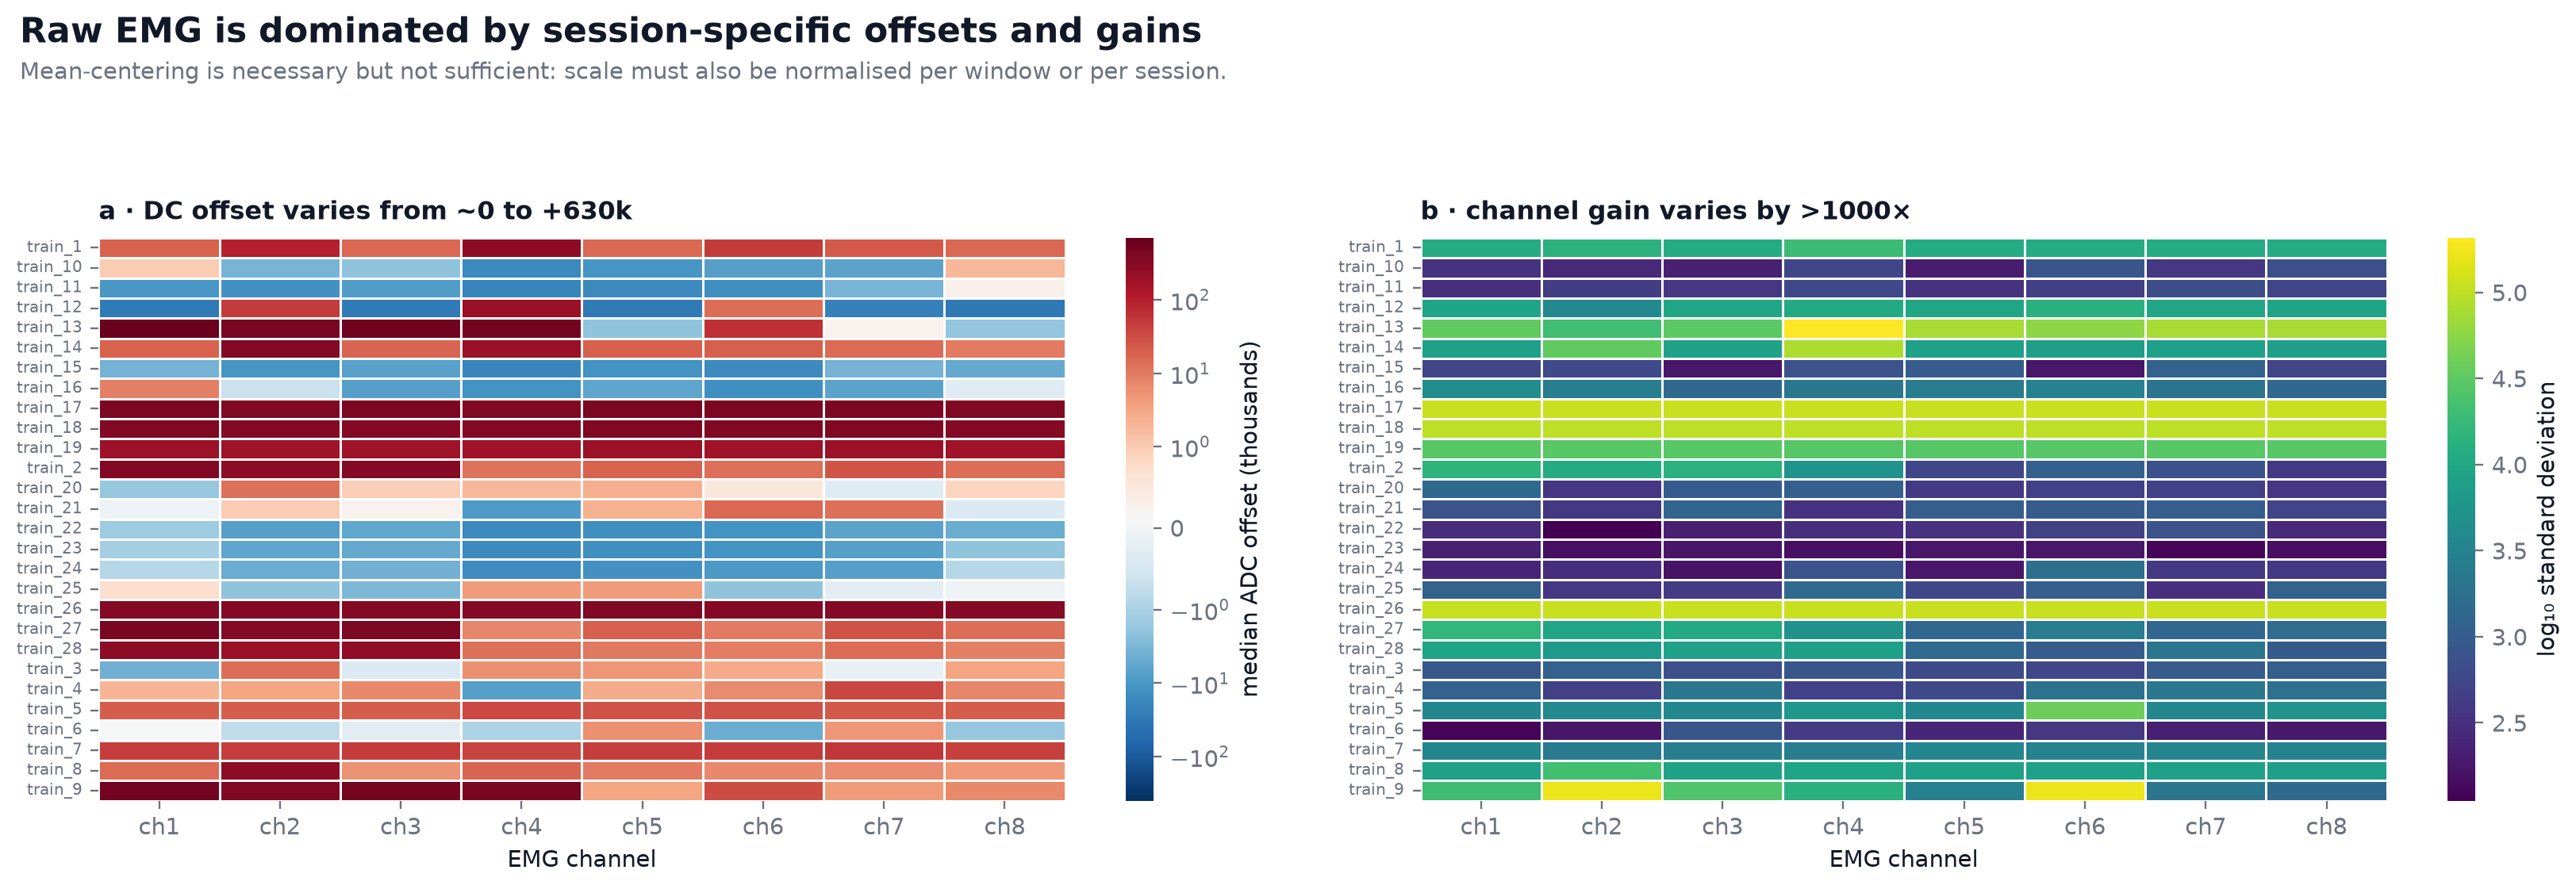

In [16]:
session_median = train.groupby("file")[EMG].median()
session_std = train.groupby("file")[EMG].std()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))
sns.heatmap(session_median / 1000, cmap="RdBu_r",
            norm=SymLogNorm(linthresh=1, vmin=-400, vmax=700),
            linewidths=0.5, linecolor="white", ax=axes[0],
            cbar_kws={"label": "median ADC offset (thousands)"})
axes[0].set_xlabel("EMG channel"); axes[0].set_ylabel("")
axes[0].tick_params(axis="y", labelsize=7)
panel_title(axes[0], "a · DC offset varies from ~0 to +630k")

sns.heatmap(np.log10(session_std), cmap="viridis", linewidths=0.5, linecolor="white",
            ax=axes[1], cbar_kws={"label": "log₁₀ standard deviation"})
axes[1].set_xlabel("EMG channel"); axes[1].set_ylabel("")
axes[1].tick_params(axis="y", labelsize=7)
panel_title(axes[1], "b · channel gain varies by >1000×")

fig.suptitle("Raw EMG is dominated by session-specific offsets and gains",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.91, "Mean-centering is necessary but not sufficient: scale must also be "
         "normalised per window or per session.", fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.87])
savefig(fig, "07_dc_offsets")

In [17]:
print("median offset range: "
      f"{session_median.min().min():,.0f} … {session_median.max().max():,.0f} ADC counts")
print("raw std range: "
      f"{session_std.min().min():,.0f} … {session_std.max().max():,.0f} ADC counts "
      f"(ratio {session_std.max().max()/session_std.min().min():.0f}×)")

median offset range: -32,588 … 632,180 ADC counts
raw std range: 112 … 207,506 ADC counts (ratio 1858×)


### 4.1 · Saturation and dropouts

Two failure modes are visible in the raw files: an ADC ceiling near **600,000 counts**,
and occasional multi-second recording gaps.

saved → graphs/data_analysis/08_signal_quality.png


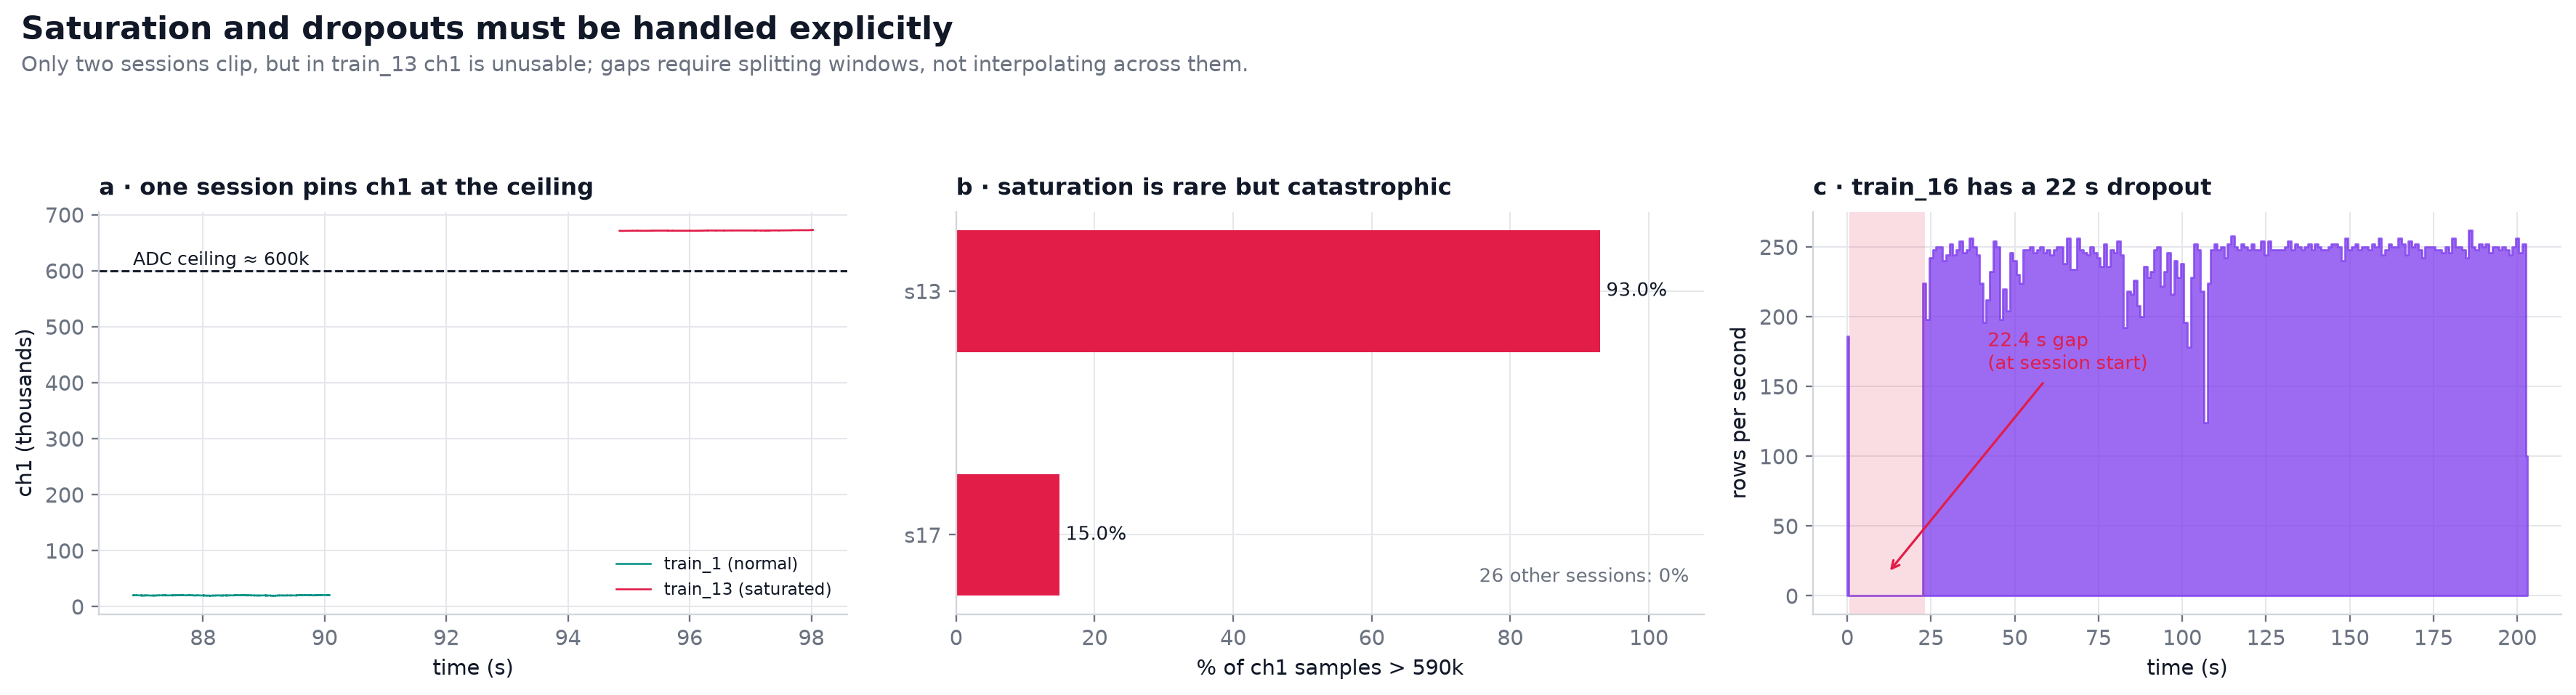

In [18]:
sat = train.assign(hot=train.ch1 > 590_000).groupby("file").hot.mean().sort_values()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# (a) saturated vs normal trace, sampled mid-session where train_13 is saturated
t13 = train[train.file == "train_13"].sort_values("row").iloc[20000:20800]
t01 = train[train.file == "train_1"].sort_values("row").iloc[20000:20800]
axes[0].plot(t01.t, t01.ch1 / 1000, color="#0d9488", lw=0.9, label="train_1 (normal)")
axes[0].plot(t13.t, t13.ch1 / 1000, color="#e11d48", lw=0.9, label="train_13 (saturated)")
axes[0].axhline(600, color=INK, ls="--", lw=1)
axes[0].text(t01.t.min(), 610, "ADC ceiling ≈ 600k", fontsize=8.5, color=INK)
axes[0].set_xlabel("time (s)"); axes[0].set_ylabel("ch1 (thousands)")
axes[0].legend(fontsize=8, loc="lower right")
panel_title(axes[0], "a · one session pins ch1 at the ceiling")

# (b) only sessions that actually saturate (the rest are exactly 0%)
sat_pos = sat[sat > 0]
axes[1].barh(np.arange(len(sat_pos)), sat_pos.values * 100, color="#e11d48", height=0.5)
axes[1].set_yticks(range(len(sat_pos)), [f.replace("train_", "s") for f in sat_pos.index])
axes[1].set_xlabel("% of ch1 samples > 590k")
for i, v in enumerate(sat_pos.values):
    axes[1].text(v * 100, i, f" {v:.1%}", va="center", fontsize=9)
axes[1].set_xlim(0, 108)
axes[1].text(0.98, 0.08, f"{len(sat) - len(sat_pos)} other sessions: 0%",
             transform=axes[1].transAxes, ha="right", fontsize=9, color=MUTED)
panel_title(axes[1], "b · saturation is rare but catastrophic")

# (c) dropout timeline (the gap sits at the very start of train_16)
d16 = train[train.file == "train_16"].sort_values("row")
per_sec = d16.groupby(d16.t.astype(int)).size().reindex(range(0, 204), fill_value=0)
axes[2].fill_between(per_sec.index, per_sec.values, color="#7c3aed", alpha=0.75, step="mid")
axes[2].set_xlabel("time (s)"); axes[2].set_ylabel("rows per second")
dt16 = d16.t.diff().values
gap_idx = int(np.nanargmax(dt16))
gap_start = float(d16.t.iloc[gap_idx - 1])
gap_end = float(d16.t.iloc[gap_idx])
gap_mid = (gap_start + gap_end) / 2
axes[2].axvspan(gap_start, gap_end, color="#e11d48", alpha=0.15, lw=0)
axes[2].annotate(f"{gap_end - gap_start:.1f} s gap\n(at session start)",
                 xy=(gap_mid, per_sec.max() * 0.06),
                 xytext=(gap_mid + 30, per_sec.max() * 0.62),
                 fontsize=9, color="#e11d48",
                 arrowprops=dict(arrowstyle="->", color="#e11d48", lw=1.1))
panel_title(axes[2], "c · train_16 has a 22 s dropout")

fig.suptitle("Saturation and dropouts must be handled explicitly",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Only two sessions clip, but in train_13 ch1 is unusable; gaps "
         "require splitting windows, not interpolating across them.",
         fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "08_signal_quality")

In [19]:
print(pd.DataFrame({"share_ch1_>590k": sat.round(4)}).loc[lambda d: d.iloc[:, 0] > 0].to_string())
print("\nrecording gaps > 0.5 s:")
for f, d in train.groupby("file"):
    d = d.sort_values("row")
    dt = d.t.diff()
    if (dt > 0.5).any():
        print(f"  {f}: max gap {dt.max():.2f} s, n>0.5s = {(dt > 0.5).sum()}")
print("\nsignal NaNs:", int(train[SIG].isna().sum().sum()))

          share_ch1_>590k
file                     
train_17           0.1497
train_13           0.9303

recording gaps > 0.5 s:
  train_16: max gap 22.44 s, n>0.5s = 1
  train_17: max gap 0.52 s, n>0.5s = 1
  train_25: max gap 4.08 s, n>0.5s = 1
  train_5: max gap 0.55 s, n>0.5s = 1

signal NaNs: 0


**Interpretation — §4.1**

* **`train_13` ch1 is saturated for 93% of its samples** (median 632k > 600k ceiling).
  `train_17` saturates 15% of ch1. Both should either be dropped from ch1-dependent
  models or have ch1 masked. Other channels are clean.
* No signal column contains NaNs and no channel is dead; the 0.3–0.6% "flat" samples are
  isolated held values, not broken sensors.
* Dropouts are rare but real: **22.4 s** (`train_16`), **4.1 s** (`train_25`), ~0.5 s in
  `train_5`/`train_17`. Windows must break at gaps. Never interpolate across a 22 s hole —
  the gesture in between is simply missing.

### 4.2 · Spectrum: mains hum and session-dependent bandwidth

The effective Nyquist frequency is only **~115 Hz** (rate ~230 Hz), so we see the low end
of the EMG spectrum. A broad ridge near 50 Hz indicates mains interference.

saved → graphs/data_analysis/09_spectra.png


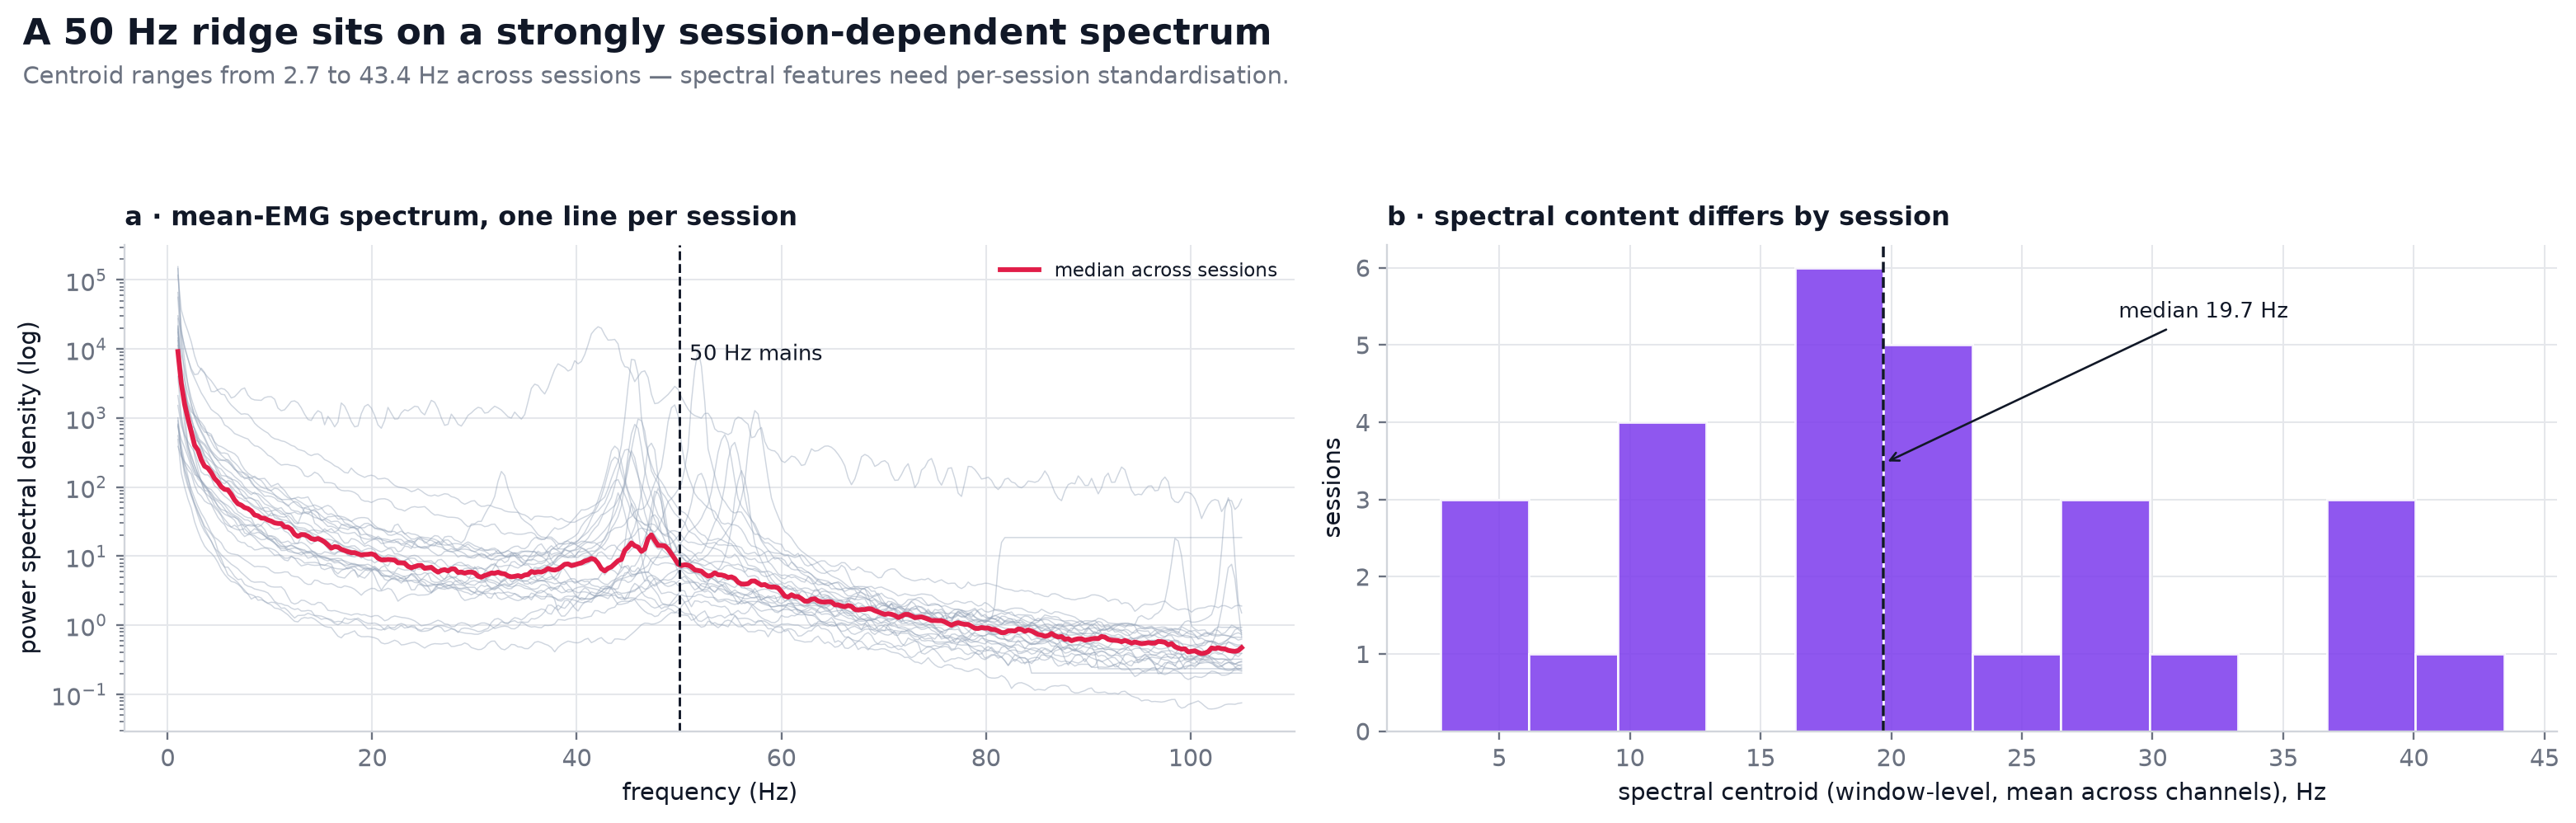

In [20]:
grid = np.linspace(1, 105, 320)
psd_all = []
for f, d in train.groupby("file"):
    rate = len(d) / (d.t.max() - d.t.min())
    fr, p = signal.welch(d[EMG].mean(axis=1).values, fs=rate, nperseg=512,
                         detrend="constant")
    psd_all.append(np.interp(grid, fr, p))
psd_all = np.array(psd_all)
psd_med = np.median(psd_all, axis=0)

centroid = []
for w in windows.itertuples():
    x = arrays[w.file][w.start:w.start + w.W, :8]      # EMG only
    xc = x - x.mean(axis=0)
    fr, p = signal.welch(xc, fs=w.rate, nperseg=min(128, w.W), detrend="constant", axis=0)
    tot = p.sum(axis=0) + 1e-12
    centroid.append(np.mean((fr[:, None] * p).sum(axis=0) / tot))
centroid = pd.Series(centroid).groupby(windows.file).median()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for p in psd_all:
    axes[0].plot(grid, p, color="#94a3b8", lw=0.5, alpha=0.45)
axes[0].plot(grid, psd_med, color="#e11d48", lw=2, label="median across sessions")
axes[0].axvline(50, color=INK, ls="--", lw=1)
axes[0].text(51, psd_med.max() * 0.75, "50 Hz mains", fontsize=9, color=INK)
axes[0].set_yscale("log"); axes[0].set_xlabel("frequency (Hz)")
axes[0].set_ylabel("power spectral density (log)")
axes[0].legend(fontsize=8)
panel_title(axes[0], "a · mean-EMG spectrum, one line per session")

axes[1].hist(centroid, bins=12, color="#7c3aed", alpha=0.85, edgecolor="white")
axes[1].axvline(centroid.median(), color=INK, ls="--", lw=1.2)
axes[1].annotate(f"median {centroid.median():.1f} Hz",
                 xy=(centroid.median(), 0.55), xycoords=("data", "axes fraction"),
                 xytext=(centroid.median() + 9, 0.85),
                 textcoords=("data", "axes fraction"), fontsize=9,
                 arrowprops=dict(arrowstyle="->", color=INK, lw=0.9))
axes[1].set_xlabel("spectral centroid (window-level, mean across channels), Hz")
axes[1].set_ylabel("sessions")
panel_title(axes[1], "b · spectral content differs by session")

fig.suptitle("A 50 Hz ridge sits on a strongly session-dependent spectrum",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Centroid ranges from 2.7 to 43.4 Hz across sessions — spectral "
         "features need per-session standardisation.", fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "09_spectra")

In [21]:
i50 = np.argmin(abs(grid - 50))
nb50 = (abs(grid - 50) > 4) & (abs(grid - 50) < 11)
ratio50 = psd_all[:, i50] / np.median(psd_all[:, nb50], axis=1)
print(f"spectral centroid per session: {centroid.min():.1f}–{centroid.max():.1f} Hz "
      f"(median {centroid.median():.1f})")
print(f"50 Hz power / local median: {np.median(ratio50):.2f} (session median); "
      f"{int((ratio50 > 1.1).sum())}/{len(ratio50)} sessions > 1.1")
from scipy.stats import spearmanr
rho_rate, p_rate = spearmanr(train_rate, centroid)
print(f"Spearman(rate, centroid): rho={rho_rate:.2f}, p={p_rate:.3f}")

spectral centroid per session: 2.7–43.4 Hz (median 19.7)
50 Hz power / local median: 1.37 (session median); 17/28 sessions > 1.1
Spearman(rate, centroid): rho=0.36, p=0.060


**Interpretation — §4.2**

* A **50 Hz ridge** is visible in the session-median spectrum (≈1.3× the local median),
  and **17 of 28 sessions** show a per-session ratio above 1.1; one session is hugely
  contaminated (≈74× at 49.6 Hz), while others show little or none. A notch at 50 Hz (and
  its 100 Hz harmonic if visible) is cheap insurance, not a guaranteed fix.
* The **spectral centroid varies 2.7–43.4 Hz across sessions**. Sampling rate explains
  only part of this spread (Spearman ρ = 0.36, p = 0.060) — electrode contact, filtering,
  and muscle composition also contribute. Spectral features must be normalised per
  session, or they become session fingerprints.
* Because Nyquist is only ~115 Hz, high-frequency EMG information is unavailable. Models
  should not expect the usual 20–450 Hz EMG band.

## 5 · What actually separates the gestures?

A useful decomposition: does gesture identity live in **how loud** the signal is, in
**which channel** is active, in **spectral shape**, or in **temporal dynamics**?

feature table: 3,125 windows × 100 features


saved → graphs/data_analysis/10_gesture_amplitude.png


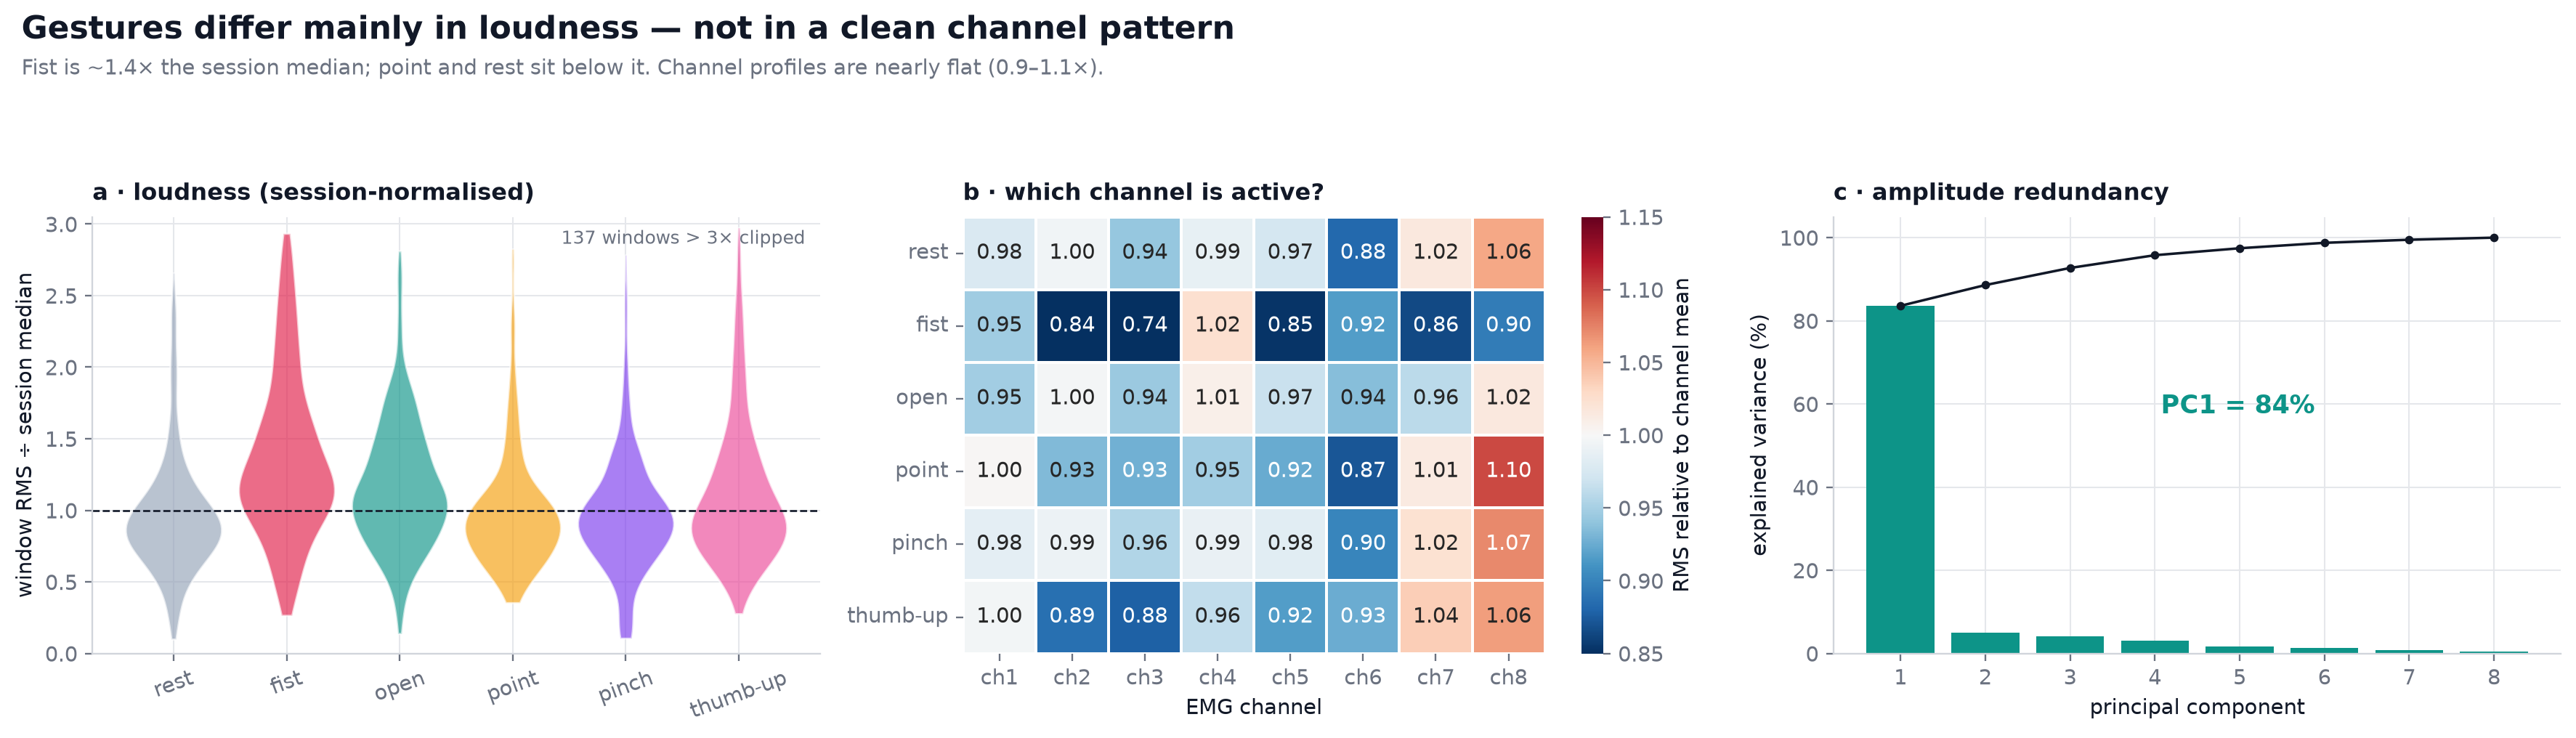

In [22]:
# Feature table for every window (used for the rest of the notebook).
feat_rows = []
for w in windows.itertuples():
    x = arrays[w.file][w.start:w.start + w.W]
    feat_rows.append({**window_features(x, w.rate), "y": w.label, "file": w.file})
feats = pd.DataFrame(feat_rows)
print(f"feature table: {feats.shape[0]:,} windows × {feats.shape[1]-2} features")

# per-session normalised loudness
feats["rms_mean"] = np.exp(feats[[f"lrms_{c}" for c in EMG]]).mean(axis=1)
feats["rms_norm"] = feats.rms_mean / feats.groupby("file").rms_mean.transform("median")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))

# (a) loudness by class (violins clipped at 3× so the bulk is legible)
CLIP = 3.0
data_all = [feats.loc[feats.y == c, "rms_norm"].values for c in CLASS_ORDER]
n_clipped = int(sum((d > CLIP).sum() for d in data_all))
data = [d[d <= CLIP] for d in data_all]
parts = axes[0].violinplot(data, showextrema=False, widths=0.85)
for pc, c in zip(parts["bodies"], CLASS_ORDER):
    pc.set_facecolor(CLASS_COLORS[c]); pc.set_alpha(0.65); pc.set_edgecolor("white")
axes[0].axhline(1, color=INK, ls="--", lw=0.9)
axes[0].set_xticks(range(1, 7), CLASS_ORDER, rotation=20)
axes[0].set_ylabel("window RMS ÷ session median")
axes[0].set_ylim(0, CLIP + 0.05)
axes[0].text(0.98, 0.97, f"{n_clipped} windows > {CLIP:.0f}× clipped",
             transform=axes[0].transAxes, ha="right", va="top", fontsize=8.5, color=MUTED)
panel_title(axes[0], "a · loudness (session-normalised)")

# (b) relative channel activation
rel = feats[[f"rel_{c}" for c in EMG]].groupby(feats.y).median().reindex(CLASS_ORDER)
rel_exp = np.exp(rel)
sns.heatmap(rel_exp, annot=True, fmt=".2f", cmap="RdBu_r", center=1.0,
            vmin=0.85, vmax=1.15, linewidths=0.8, linecolor="white",
            cbar_kws={"label": "RMS relative to channel mean"}, ax=axes[1])
axes[1].set_xlabel("EMG channel"); axes[1].set_ylabel("")
axes[1].set_xticklabels(EMG, rotation=0)
axes[1].set_yticklabels(CLASS_ORDER, rotation=0)
panel_title(axes[1], "b · which channel is active?")

# (c) PCA of log-RMS: one common-mode factor
pca = PCA().fit(feats[[f"lrms_{c}" for c in EMG]].values)
axes[2].bar(np.arange(1, 9), pca.explained_variance_ratio_ * 100, color="#0d9488")
axes[2].plot(np.arange(1, 9), np.cumsum(pca.explained_variance_ratio_) * 100,
             color=INK, marker="o", ms=3, lw=1.2)
axes[2].set_xlabel("principal component"); axes[2].set_ylabel("explained variance (%)")
axes[2].set_ylim(0, 105)
axes[2].text(0.45, 0.55, f"PC1 = {pca.explained_variance_ratio_[0]:.0%}",
             transform=axes[2].transAxes, fontsize=12, fontweight="bold", color="#0d9488")
panel_title(axes[2], "c · amplitude redundancy")

fig.suptitle("Gestures differ mainly in loudness — not in a clean channel pattern",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Fist is ~1.4× the session median; point and rest sit below it. "
         "Channel profiles are nearly flat (0.9–1.1×).", fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "10_gesture_amplitude")

In [23]:
print("session-normalised loudness (median):")
print(feats.groupby("y").rms_norm.median().reindex(CLASS_ORDER).round(2).to_string())
print(f"\nPC1 explains {pca.explained_variance_ratio_[0]:.1%} of log-RMS variance")

session-normalised loudness (median):
y
rest        0.90
fist        1.40
open        1.12
point       0.91
pinch       0.93
thumb-up    1.00

PC1 explains 83.6% of log-RMS variance


### 5.1 · Statistical checks

Two questions are worth testing formally, with the **session** as the unit of
inference (windows overlap and are not independent):

1. Do the eight channels have systematically different gains? → **Friedman test** on
   per-session median log-RMS (repeated measures, no normality assumption).
2. Is rest quieter than gestures? → **Wilcoxon signed-rank** on paired per-session
   medians.

In [24]:
# 1) channel gains (each session contributes one median per channel)
chan_med = feats.groupby("file")[[f"lrms_{c}" for c in EMG]].median()
stat, p_fried = friedmanchisquare(*[chan_med[c].values for c in chan_med.columns])
kendall_w = stat / (len(chan_med) * (len(chan_med.columns) - 1))
print(f"Friedman channel-gain test: χ²={stat:.1f}, df=7, p={p_fried:.2e}, "
      f"Kendall's W={kendall_w:.3f}  (n=28 sessions)")

# 2) rest vs gesture loudness (paired by session)
med = feats.groupby(["file", "y"]).rms_norm.median().unstack()
rest, gest = med["rest"], med.drop(columns="rest").median(axis=1)
stat_w, p_w = wilcoxon(rest, gest, alternative="less")
print(f"Wilcoxon rest < gestures: n=28 pairs, W={stat_w:.0f}, p={p_w:.2e}, "
      f"median ratio={np.exp(np.log(rest / gest).median()):.2f}")

# 3) class mix across sessions (design check; not a random-sampling test)
ct = pd.crosstab(windows.file, windows.label)
chi2, p_chi, dof, exp = chi2_contingency(ct)
cramer_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"Class-mix χ² across sessions: χ²={chi2:.1f}, df={dof}, p={p_chi:.2f}, "
      f"Cramér's V={cramer_v:.3f}, min expected={exp.min():.1f}")

Friedman channel-gain test: χ²=22.4, df=7, p=2.15e-03, Kendall's W=0.114  (n=28 sessions)
Wilcoxon rest < gestures: n=28 pairs, W=28, p=5.52e-06, median ratio=0.91
Class-mix χ² across sessions: χ²=51.1, df=135, p=1.00, Cramér's V=0.057, min expected=15.3


**Interpretation — §5.1**

* **Channel gains differ** (Friedman p ≈ 2×10⁻³) but the effect is small
  (Kendall's W ≈ 0.11): the eight electrodes are not strongly specialised. PC1 of the
  log-RMS vector explains **84%** of variance — all channels rise and fall together.
* **Rest is significantly quieter than gestures** (Wilcoxon p ≈ 6×10⁻⁶, median ratio
  ≈ 0.91), but the effect is modest. Rest is not a "silence" class: point is just as
  quiet. Loudness alone cannot solve the task.
* **Class mix is consistent across sessions** (χ² p = 1.0, Cramér's V = 0.06, all
  expected counts > 15). This is a design property, not evidence of sampling from a
  population — interpret it as "the protocol was balanced", not as a hypothesis test.
* **Validity note:** these tests use one summary per session (n = 28). Running them on
  the 3,125 windows would pseudo-replicate overlapping data and produce spuriously tiny
  p-values.

### 5.2 · IMU: a placement fingerprint more than a gesture signal

The accelerometer includes gravity. Because the device sits differently on every person,
the mean accelerometer vector identifies the session. Mean-centering removes exactly that
offset — which is why the test set does it.

saved → graphs/data_analysis/11_imu.png


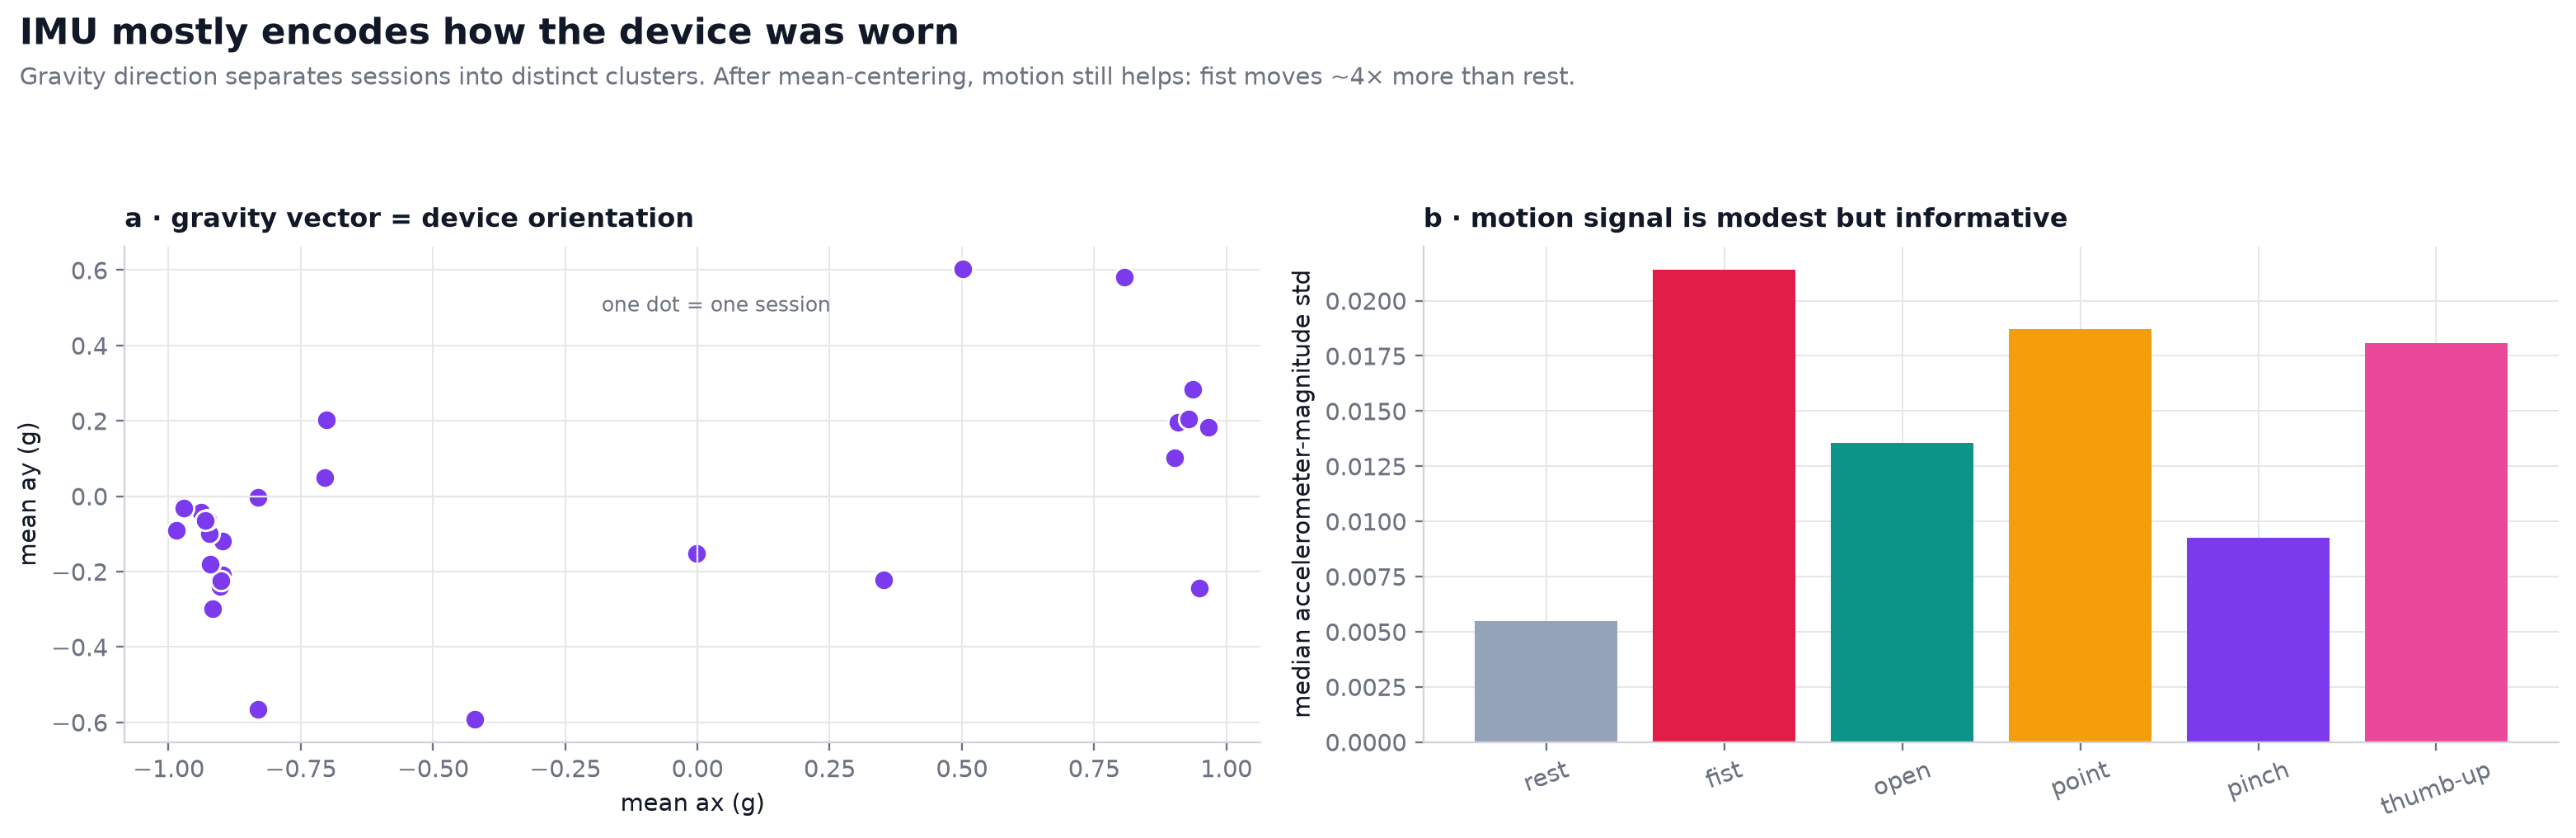

In [25]:
grav = train.groupby("file")[["ax", "ay", "az"]].median()
imu_std = feats.groupby("y")["accmag_std"].median().reindex(CLASS_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.9))

axes[0].scatter(grav.ax, grav.ay, s=70, c="#7c3aed", edgecolor="white", linewidth=1)
axes[0].set_xlabel("mean ax (g)"); axes[0].set_ylabel("mean ay (g)")
axes[0].axhline(0, color=FAINT, lw=0.8); axes[0].axvline(0, color=FAINT, lw=0.8)
axes[0].text(0.42, 0.90, "one dot = one session", transform=axes[0].transAxes,
             ha="left", va="top", fontsize=8.5, color=MUTED)
panel_title(axes[0], "a · gravity vector = device orientation")

axes[1].bar(CLASS_ORDER, imu_std.values, color=[CLASS_COLORS[c] for c in CLASS_ORDER])
axes[1].set_ylabel("median accelerometer-magnitude std")
axes[1].set_xticks(range(6), CLASS_ORDER, rotation=20)
panel_title(axes[1], "b · motion signal is modest but informative")

fig.suptitle("IMU mostly encodes how the device was worn",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Gravity direction separates sessions into distinct clusters. "
         "After mean-centering, motion still helps: fist moves ~4× more than rest.",
         fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "11_imu")

In [26]:
print("accelerometer magnitude std by class:")
print(imu_std.round(4).to_string())
print(f"\ngravity vectors span ax {grav.ax.min():+.2f}…{grav.ax.max():+.2f} g, "
      f"ay {grav.ay.min():+.2f}…{grav.ay.max():+.2f} g")

accelerometer magnitude std by class:
y
rest        0.0055
fist        0.0214
open        0.0136
point       0.0187
pinch       0.0092
thumb-up    0.0181

gravity vectors span ax -0.99…+0.97 g, ay -0.59…+0.60 g


**Interpretation — §5.2**

* Gravity direction varies widely (ax from −1 to +1 g), creating **distinct session
  clusters**. A model fed raw `ax, ay, az` can learn *who is wearing the device* instead
  of *what the hand is doing*.
* The organisers' per-action mean-centering removes this offset. Reproduce it exactly:
  **subtract each channel's mean within each window**. Do not use a global scaler fitted
  on training sessions — it would reintroduce the offset.
* Gyroscope medians are biased too (≈ [1.4, −5.1, −0.3] °/s across almost every session),
  another constant that centering removes.
* After centering, accelerometer motion is modest but genuinely informative — fist moves
  ~4× more than rest — and an IMU-only baseline reaches macro-F1 ≈ 0.25. Treat IMU as a
  complementary channel, not a replacement for EMG.

## 6 · Training vs test: are they comparable?

We cannot check labels, but we can compare *distributions* at the session level. With
28 training sessions and 5 test files, any test has low power — so effect sizes and
multiple-comparison control matter more than p-values.

saved → graphs/data_analysis/12_train_test_shift.png


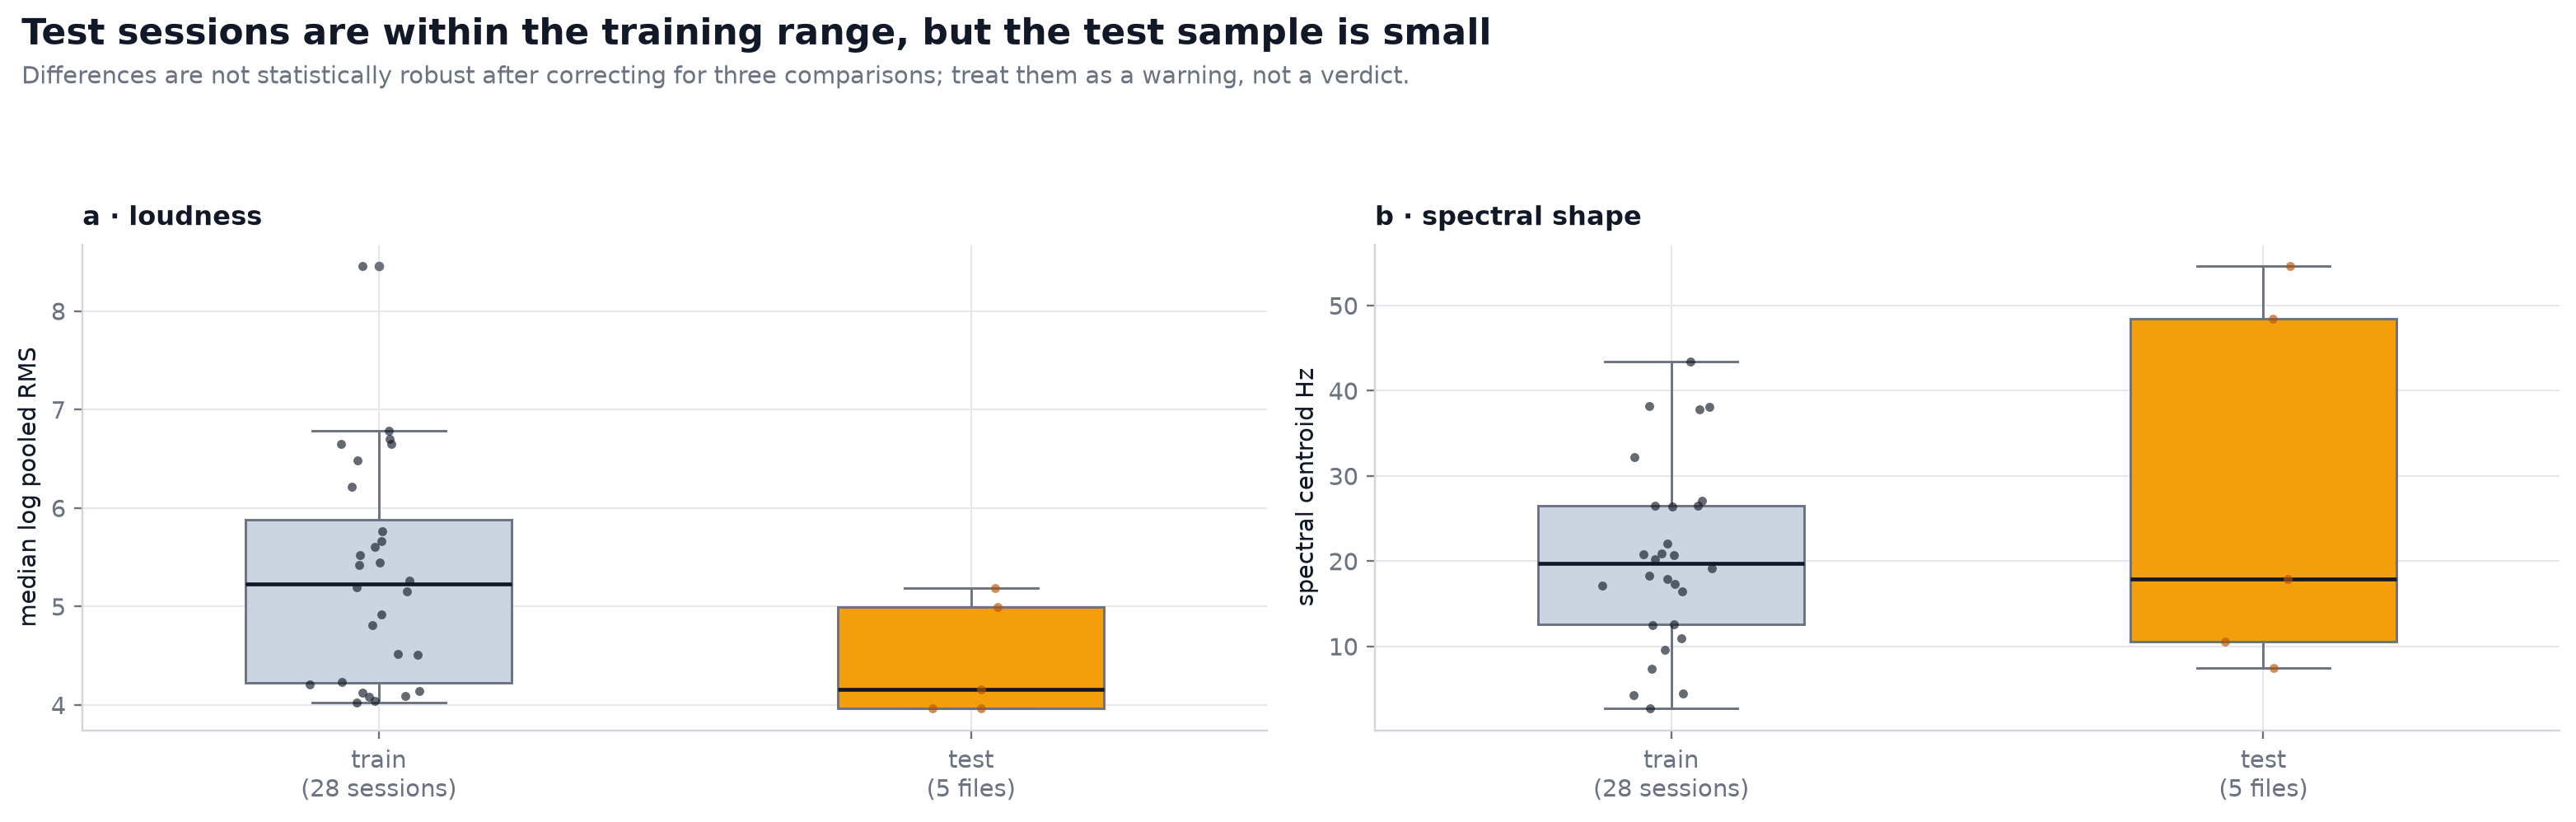

In [27]:
# Loudness on a comparable scale: pooled RMS over the 8 EMG channels, then log.
train_loud = np.log(np.sqrt((np.exp(feats[[f"lrms_{c}" for c in EMG]]) ** 2).mean(axis=1)))
train_loud = train_loud.groupby(feats.file).median()

tmp = test.groupby("action_id").agg(file=("file", "first"))
action_rms = (test.assign(_sq=(test[EMG] ** 2).mean(axis=1))
                  .groupby("action_id")["_sq"].mean().pow(0.5))
tmp["log_rms"] = np.log(action_rms)
test_loud = tmp.groupby("file").log_rms.median()

cent_test = []
for f, d in test.groupby("file"):
    vals = []
    for a, g in d.groupby("action_id"):
        rate = len(g) / g.t.max()
        fr, p = signal.welch(g[EMG].mean(axis=1).values, fs=rate, nperseg=min(128, len(g)),
                             detrend="constant")
        vals.append((fr * p).sum() / (p.sum() + 1e-12))
    cent_test.append(np.median(vals))
cent_test = pd.Series(cent_test, index=test.groupby("file").size().index)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, train_vals, test_vals, label, unit in [
    (axes[0], train_loud, test_loud, "median log pooled RMS", ""),
    (axes[1], centroid, cent_test, "spectral centroid", " Hz"),
]:
    bp = ax.boxplot([train_vals.values, test_vals.values], widths=0.45, patch_artist=True,
                    medianprops=dict(color=INK, lw=1.6),
                    boxprops=dict(facecolor="white", edgecolor=MUTED),
                    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                    flierprops=dict(marker="o", markersize=4, markerfacecolor=MUTED,
                                    markeredgecolor="none"))
    bp["boxes"][0].set_facecolor("#cbd5e1")
    bp["boxes"][1].set_facecolor("#f59e0b")
    for i, vals in enumerate([train_vals.values, test_vals.values]):
        ax.scatter(np.random.default_rng(i).normal(i + 1, 0.05, len(vals)), vals,
                   s=14, color=INK if i == 0 else "#b45309", alpha=0.65, linewidth=0,
                   zorder=3)
    ax.set_xticks([1, 2], ["train\n(28 sessions)", "test\n(5 files)"])
    ax.set_ylabel(label + unit)
panel_title(axes[0], "a · loudness")
panel_title(axes[1], "b · spectral shape")

fig.suptitle("Test sessions are within the training range, but the test sample is small",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Differences are not statistically robust after correcting for "
         "three comparisons; treat them as a warning, not a verdict.",
         fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "12_train_test_shift")

In [28]:
print(f"test action mean-centering check: max |mean| = "
      f"{test.groupby('action_id')[SIG].mean().abs().max().max():.1e}")

test action mean-centering check: max |mean| = 5.0e-04


### 6.1 · Permutation tests at the session level

We compare the 28 training sessions with the 5 test files using a **permutation test on
the difference of medians**. This respects the session as the unit and makes no
distributional assumption. Because three features are tested, we use a Bonferroni
threshold of 0.05/3 ≈ 0.017.

In [29]:
def perm_diff(a, b, n_perm=20000, seed=0):
    """Two-sided permutation test for a difference in medians, n small."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    observed = np.median(b) - np.median(a)
    pooled = np.r_[a, b]
    rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(n_perm):
        idx = rng.choice(len(pooled), len(b), replace=False)
        d = np.median(pooled[idx]) - np.median(np.delete(pooled, idx))
        hits += abs(d) >= abs(observed)
    return observed, (hits + 1) / (n_perm + 1)

# spectral centroid and high-frequency ratio per test action, aggregated to file
rows_cent, rows_hf = [], []
for f, d in test.groupby("file"):
    cen, hf = [], []
    for a, g in d.groupby("action_id"):
        rate = len(g) / g.t.max()
        x = g[EMG].to_numpy(float)
        fr, p = signal.welch(x, fs=rate, nperseg=min(128, len(g)), detrend="constant", axis=0)
        tot = p.sum(axis=0) + 1e-12
        cen.append(np.mean((fr[:, None] * p).sum(axis=0) / tot))
        hf.append(np.mean(p[fr >= 40].sum(axis=0) / tot))
    rows_cent.append(np.median(cen))
    rows_hf.append(np.median(hf))

tr_hf = feats[[f"b_hi_{c}" for c in EMG]].mean(axis=1).groupby(feats.file).median()

print(f"{'feature':<20}{'train':>10}{'test':>10}{'diff':>10}{'p (perm)':>12}")
for name, tr_vals, te_vals in [
    ("median log-RMS", train_loud.values, test_loud.values),
    ("spectral centroid", centroid.values, np.array(rows_cent)),
    ("high-freq ratio", tr_hf.values, np.array(rows_hf)),
]:
    d, p = perm_diff(tr_vals, te_vals)
    print(f"{name:<20}{np.median(tr_vals):>10.2f}{np.median(te_vals):>10.2f}"
          f"{d:>+10.2f}{p:>12.4f}")

feature                  train      test      diff    p (perm)


median log-RMS            5.23      4.15     -1.08      0.0955


spectral centroid        19.70     28.55     +8.84      0.1075


high-freq ratio           0.31      0.50     +0.19      0.1816


**Interpretation — §6**

* The test set is **exactly mean-centred per action** (max |mean| = 5×10⁻⁴), confirming
  the organiser's preprocessing. Training windows must be centred the same way.
* Loudness and spectral shape of test sessions lie inside the training range, but two
  point estimates lean high: the spectral centroid (median 28.6 vs 19.7 Hz,
  permutation p = 0.11) and the high-frequency ratio (0.50 vs 0.31, p = 0.18). Loudness
  is lower in test (5.23 vs 4.15 log-RMS, p = 0.096). **None survives Bonferroni
  correction** (threshold 0.017), and with only five test files power is low — record
  these as cautions, not conclusions.
* **Practical takeaway:** assume mild covariate shift in spectral content. Techniques
  that are safe under shift: per-window standardisation, band ratios, channel
  correlation, and temporal features. Techniques that are fragile: absolute amplitude,
  absolute spectral bins, and anything learned from session identity.

## 7 · Leakage risks: sessions are fingerprints

The competition's whole difficulty is cross-person generalisation. If a validation split
mixes windows from the same session into train and validation, scores will be inflated
by the session signature rather than gesture skill. Let's quantify that.

saved → graphs/data_analysis/13_leakage.png


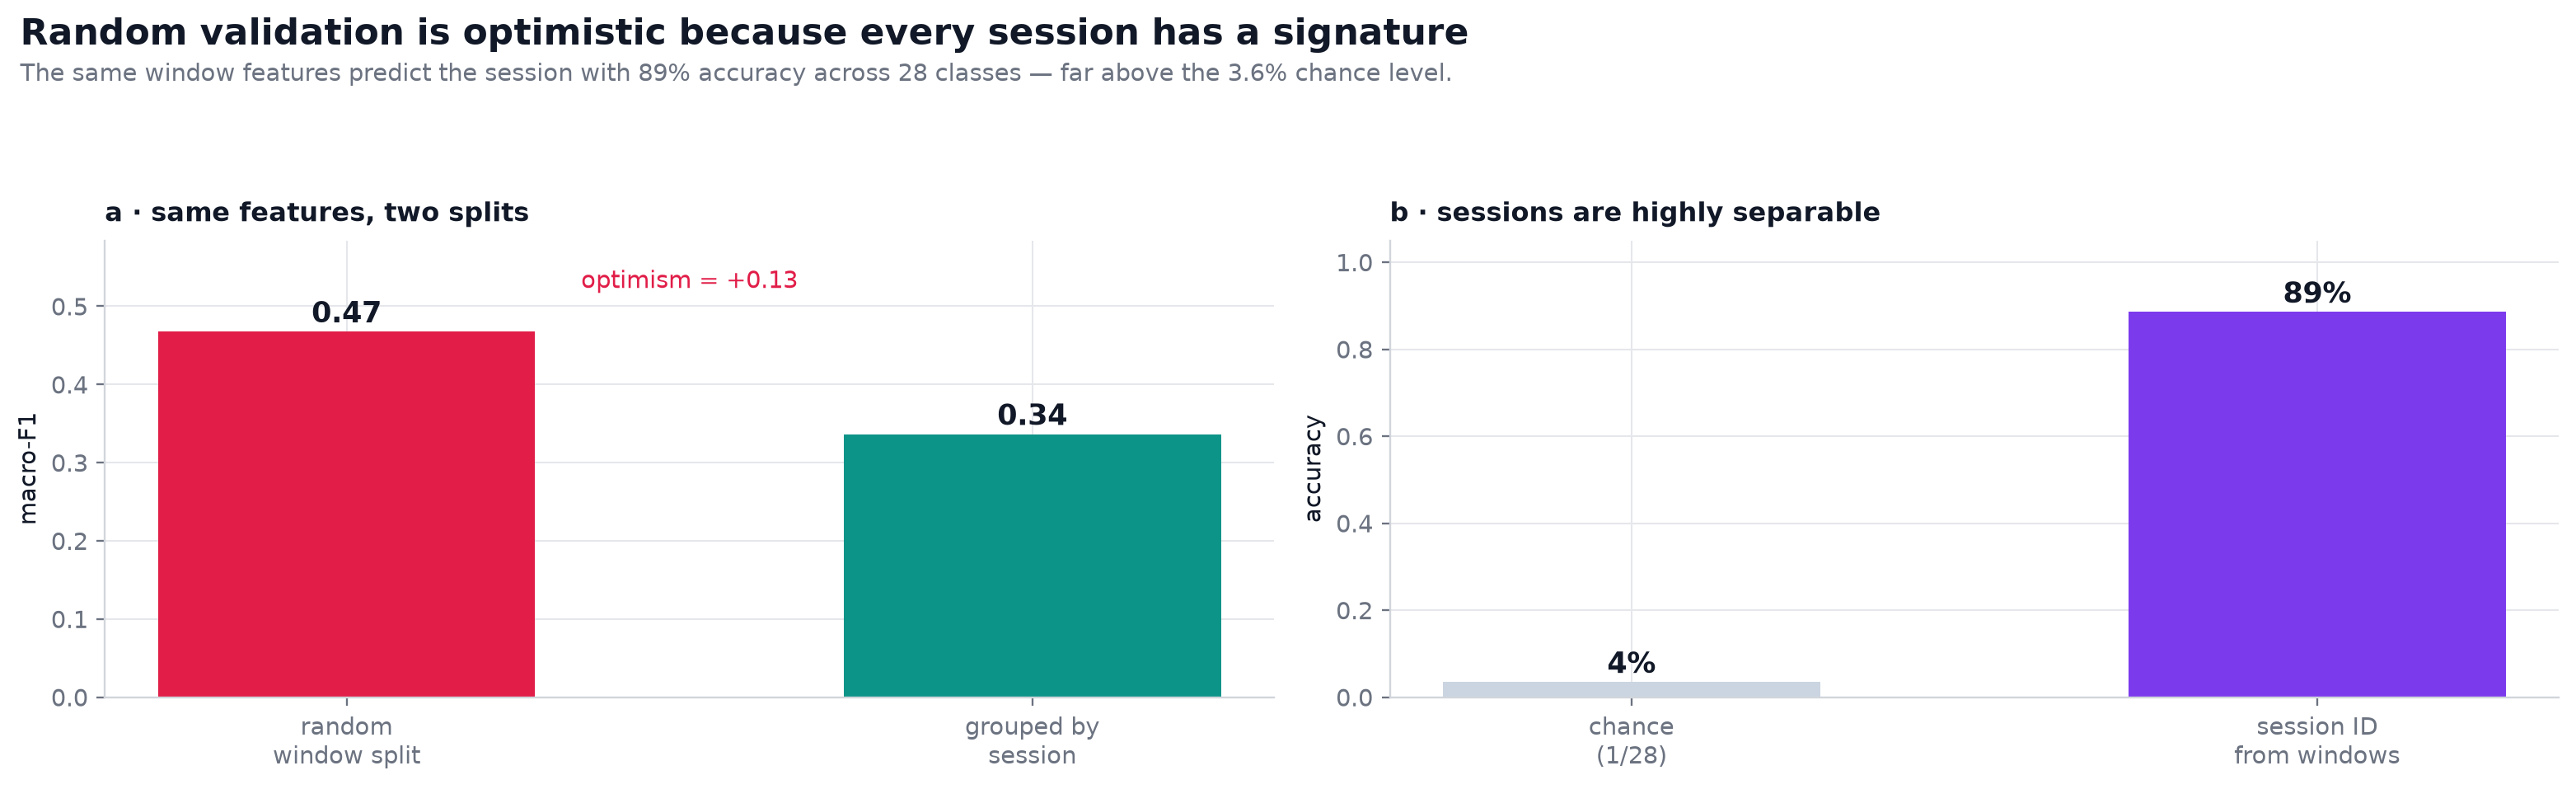

In [30]:
all_feats = [c for c in feats.columns if c not in ("y", "file", "rms_mean", "rms_norm")]
X_all, y_all, groups = feats[all_feats], feats.y, feats.file

# (a) gesture model under two validation schemes
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=4000, C=0.3))
pred_group = cross_val_predict(clf, X_all, y_all, cv=GroupKFold(5), groups=groups, n_jobs=-1)
f1_group = f1_score(y_all, pred_group, average="macro")
pred_rand = cross_val_predict(clf, X_all, y_all,
                              cv=StratifiedKFold(5, shuffle=True, random_state=0), n_jobs=-1)
f1_rand = f1_score(y_all, pred_rand, average="macro")

# (b) can a model identify the session from the same features?
pred_file = cross_val_predict(clf, X_all, groups,
                              cv=StratifiedKFold(5, shuffle=True, random_state=0), n_jobs=-1)
file_acc = accuracy_score(groups, pred_file)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
bars = axes[0].bar(["random\nwindow split", "grouped by\nsession"],
                   [f1_rand, f1_group], color=["#e11d48", "#0d9488"], width=0.55)
for b, v in zip(bars, [f1_rand, f1_group]):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.2f}",
                 ha="center", fontsize=12, fontweight="bold")
axes[0].set_ylim(0, max(f1_rand, f1_group) * 1.25)
axes[0].set_ylabel("macro-F1")
axes[0].annotate(f"optimism = +{f1_rand - f1_group:.2f}",
                 xy=(0.5, max(f1_rand, f1_group) * 1.12), ha="center",
                 fontsize=10, color="#e11d48")
panel_title(axes[0], "a · same features, two splits")

bars = axes[1].bar(["chance\n(1/28)", "session ID\nfrom windows"],
                   [1 / 28, file_acc], color=["#cbd5e1", "#7c3aed"], width=0.55)
for b, v in zip(bars, [1 / 28, file_acc]):
    axes[1].text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}",
                 ha="center", fontsize=12, fontweight="bold")
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel("accuracy")
panel_title(axes[1], "b · sessions are highly separable")

fig.suptitle("Random validation is optimistic because every session has a signature",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "The same window features predict the session with 89% accuracy "
         "across 28 classes — far above the 3.6% chance level.",
         fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "13_leakage")

In [31]:
print(f"random-split macro-F1 : {f1_rand:.3f}")
print(f"grouped-split macro-F1: {f1_group:.3f}  (optimism {f1_rand - f1_group:+.3f})")
print(f"session-ID accuracy   : {file_acc:.1%}  vs chance {1/28:.1%}")

random-split macro-F1 : 0.467
grouped-split macro-F1: 0.336  (optimism +0.131)
session-ID accuracy   : 88.7%  vs chance 3.6%


**Interpretation — §7**

* A model that has seen *any* window from a session can recognise that session from a new
  window with **89% accuracy** (28 classes). That is the leakage channel.
* Random window CV inflates gesture macro-F1 by **+0.13** (0.47 vs 0.34). The
  competition test set contains **unseen participants**, so grouped validation is the only
  honest estimate.
* **Never** use camera or hand-tracking columns as features: they exist only in training
  and encode the label directly. The test schema omits them for a reason.
* `roll/pitch/yaw`, finger-curl, and `openness` columns are label-derived or
  placement-derived. They are not sensor inputs at test time.

## 8 · A deliberately simple baseline (sanity check, not a solution)

To confirm the pipeline and calibrate expectations, we fit a multinomial logistic
regression on the window features with **session-grouped 5-fold CV**. This is a floor,
not a competitive model.

saved → graphs/data_analysis/14_baseline.png


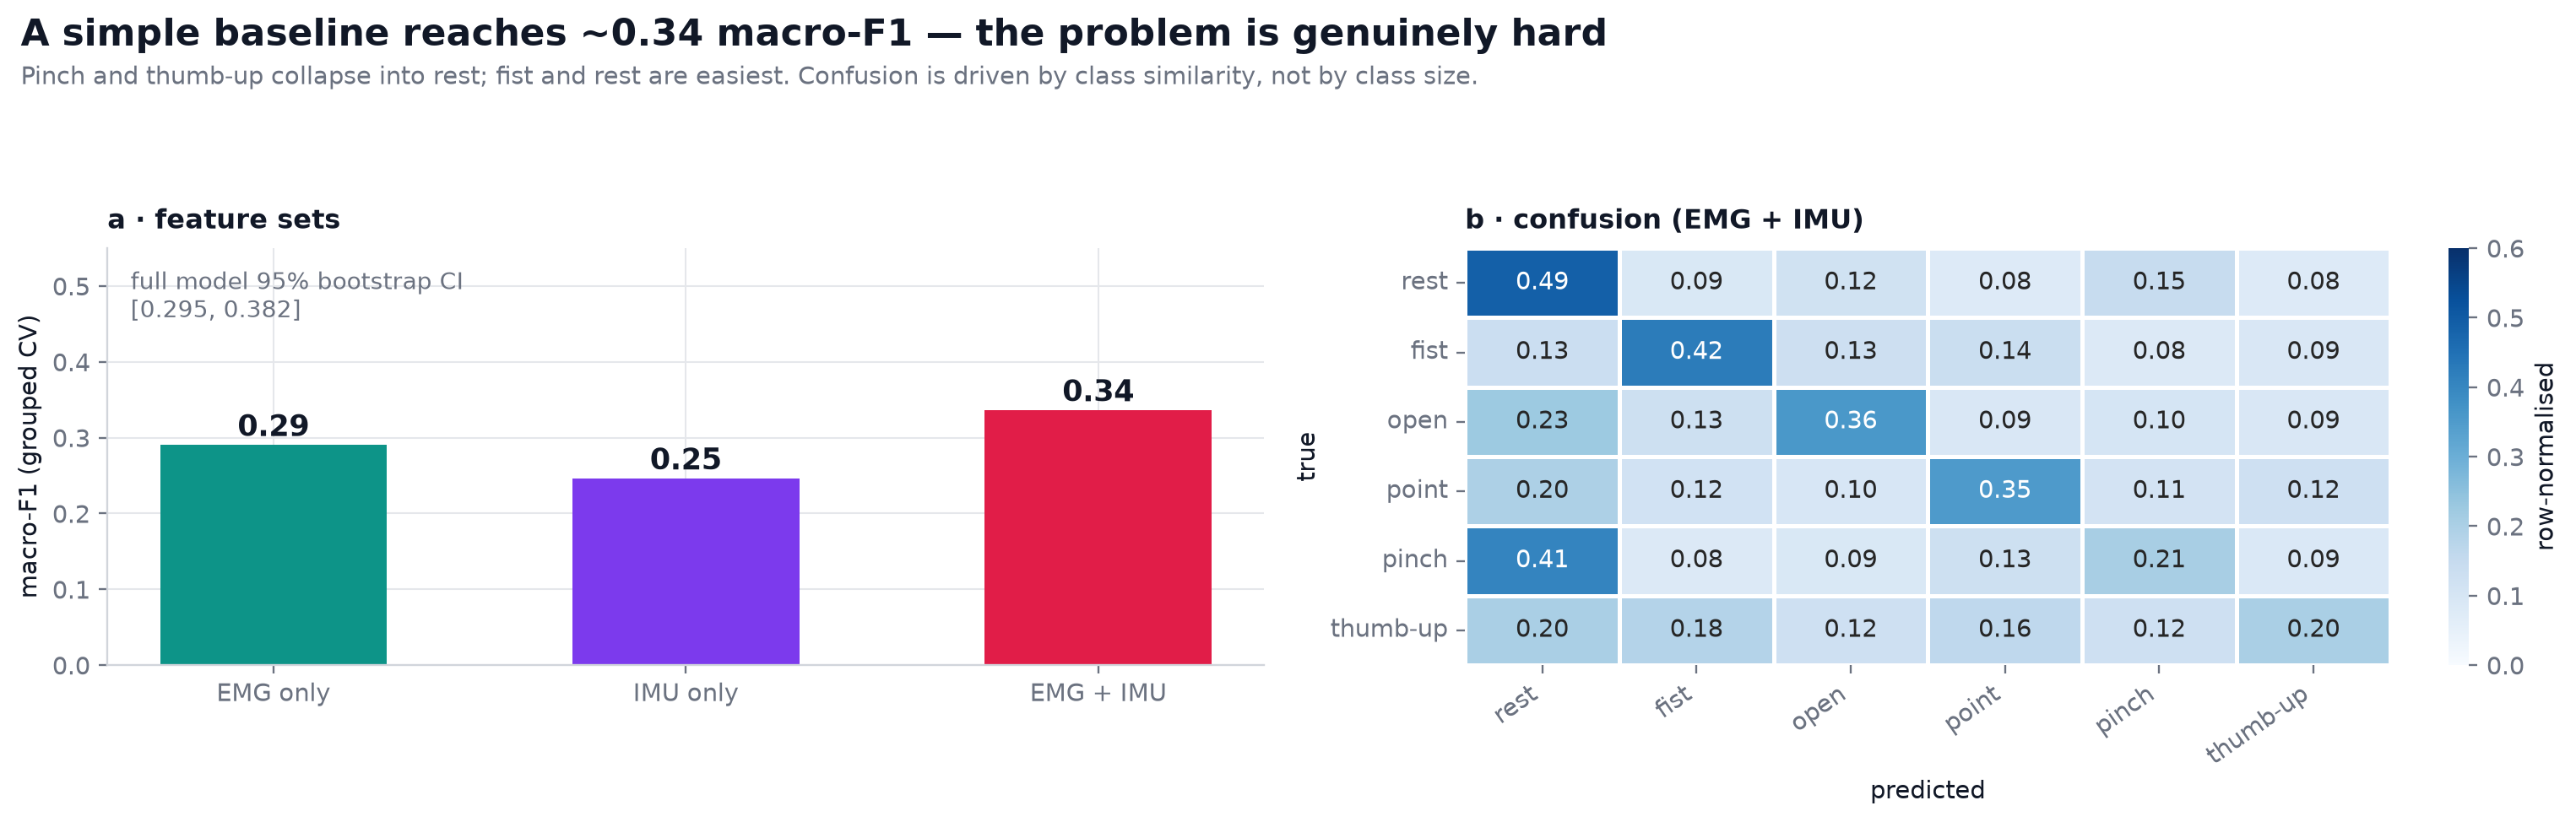

In [32]:
emg_feats = [c for c in all_feats if c.startswith(("lrms", "rel", "zcr", "wl", "cor", "cen", "b_"))]
imu_feats = [c for c in all_feats if c.startswith(("imustd", "accmag", "gyromag"))]

def grouped_f1(cols):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=4000, C=0.3))
    pred = cross_val_predict(clf, feats[cols], y_all, cv=GroupKFold(5), groups=groups, n_jobs=-1)
    return f1_score(y_all, pred, average="macro")

scores = {"EMG only": grouped_f1(emg_feats),
          "IMU only": grouped_f1(imu_feats),
          "EMG + IMU": grouped_f1(all_feats)}

# bootstrap CI over sessions for the full model
pred_full = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=4000, C=0.3)),
                              feats[all_feats], y_all, cv=GroupKFold(5), groups=groups, n_jobs=-1)
rng = np.random.default_rng(0)
boot = []
sessions = np.array(sorted(feats.file.unique()))
for _ in range(1000):
    pick = rng.choice(sessions, len(sessions), replace=True)
    mask = feats.file.isin(pick).values
    boot.append(f1_score(y_all[mask], pred_full[mask], average="macro",
                         labels=CLASS_ORDER))
lo, hi = np.percentile(boot, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.7))

bars = axes[0].bar(list(scores), list(scores.values()),
                   color=["#0d9488", "#7c3aed", "#e11d48"], width=0.55)
for b, v in zip(bars, scores.values()):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.2f}",
                 ha="center", fontsize=12, fontweight="bold")
axes[0].set_ylim(0, 0.55); axes[0].set_ylabel("macro-F1 (grouped CV)")
axes[0].text(0.02, 0.95, f"full model 95% bootstrap CI\n[{lo:.3f}, {hi:.3f}]",
             transform=axes[0].transAxes, va="top", fontsize=9.5, color=MUTED)
panel_title(axes[0], "a · feature sets")

cm = pd.crosstab(y_all, pred_full, normalize="index").reindex(index=CLASS_ORDER, columns=CLASS_ORDER)
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=0.6,
            linewidths=1.1, linecolor="white", cbar_kws={"label": "row-normalised"},
            ax=axes[1])
axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true")
axes[1].set_xticklabels(CLASS_ORDER, rotation=35, ha="right")
axes[1].set_yticklabels(CLASS_ORDER, rotation=0)
panel_title(axes[1], "b · confusion (EMG + IMU)")

fig.suptitle("A simple baseline reaches ~0.34 macro-F1 — the problem is genuinely hard",
             x=0.012, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.90, "Pinch and thumb-up collapse into rest; fist and rest are easiest. "
         "Confusion is driven by class similarity, not by class size.",
         fontsize=10, color=MUTED, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.86])
savefig(fig, "14_baseline")

In [33]:
print("grouped macro-F1 by feature set:")
for k, v in scores.items():
    print(f"  {k:<12}{v:.3f}")
print(f"full model bootstrap 95% CI: [{lo:.3f}, {hi:.3f}]")
per_class = pd.Series(f1_score(y_all, pred_full, average=None, labels=CLASS_ORDER),
                      index=CLASS_ORDER)
print("\nper-class F1:")
print(per_class.round(3).to_string())

grouped macro-F1 by feature set:
  EMG only    0.290
  IMU only    0.246
  EMG + IMU   0.336
full model bootstrap 95% CI: [0.295, 0.382]

per-class F1:
rest        0.434
fist        0.406
open        0.362
point       0.356
pinch       0.223
thumb-up    0.236


**Interpretation — §8**

* EMG carries most of the signal (**0.29**), IMU alone is weak (**0.25**), and combining
  them helps (**0.34**). The bootstrap CI **[0.295, 0.382]** is wide because there are only
  28 sessions — quote it rather than a single point estimate.
* The confusion matrix is dominated by **pinch → rest (41%)** and **thumb-up → rest
  (20%)**. These are visually similar to a relaxed hand and produce small EMG
  differences; they will need either better features (temporal, cross-channel) or
  class-specific decision thresholds.
* `rest` is the most common class yet is **not** the easiest (F1 ≈ 0.43): the model
  confuses it with pinch and open. Resampling rest does not fix this; a richer feature
  representation might.
* This baseline is a *floor*. A sequence model on resampled waveforms should beat it, but
  the grouped-CV protocol is the number to trust.

## 9 · Recommended preprocessing recipe

The recipe below follows directly from the observations above and from the competition
guide. It is written as explicit steps so it can be lifted into a training script.

Example windows:


,file,label,W,rate,t_start
1036,train_10,open,327,233.38,49.16
2060,train_19,rest,314,224.29,73.44
1946,train_18,pinch,307,219.07,75.72



unique guided rows covered: 721,805 / 925,184 (78.0%)
saved → graphs/data_analysis/15_preprocessing.png


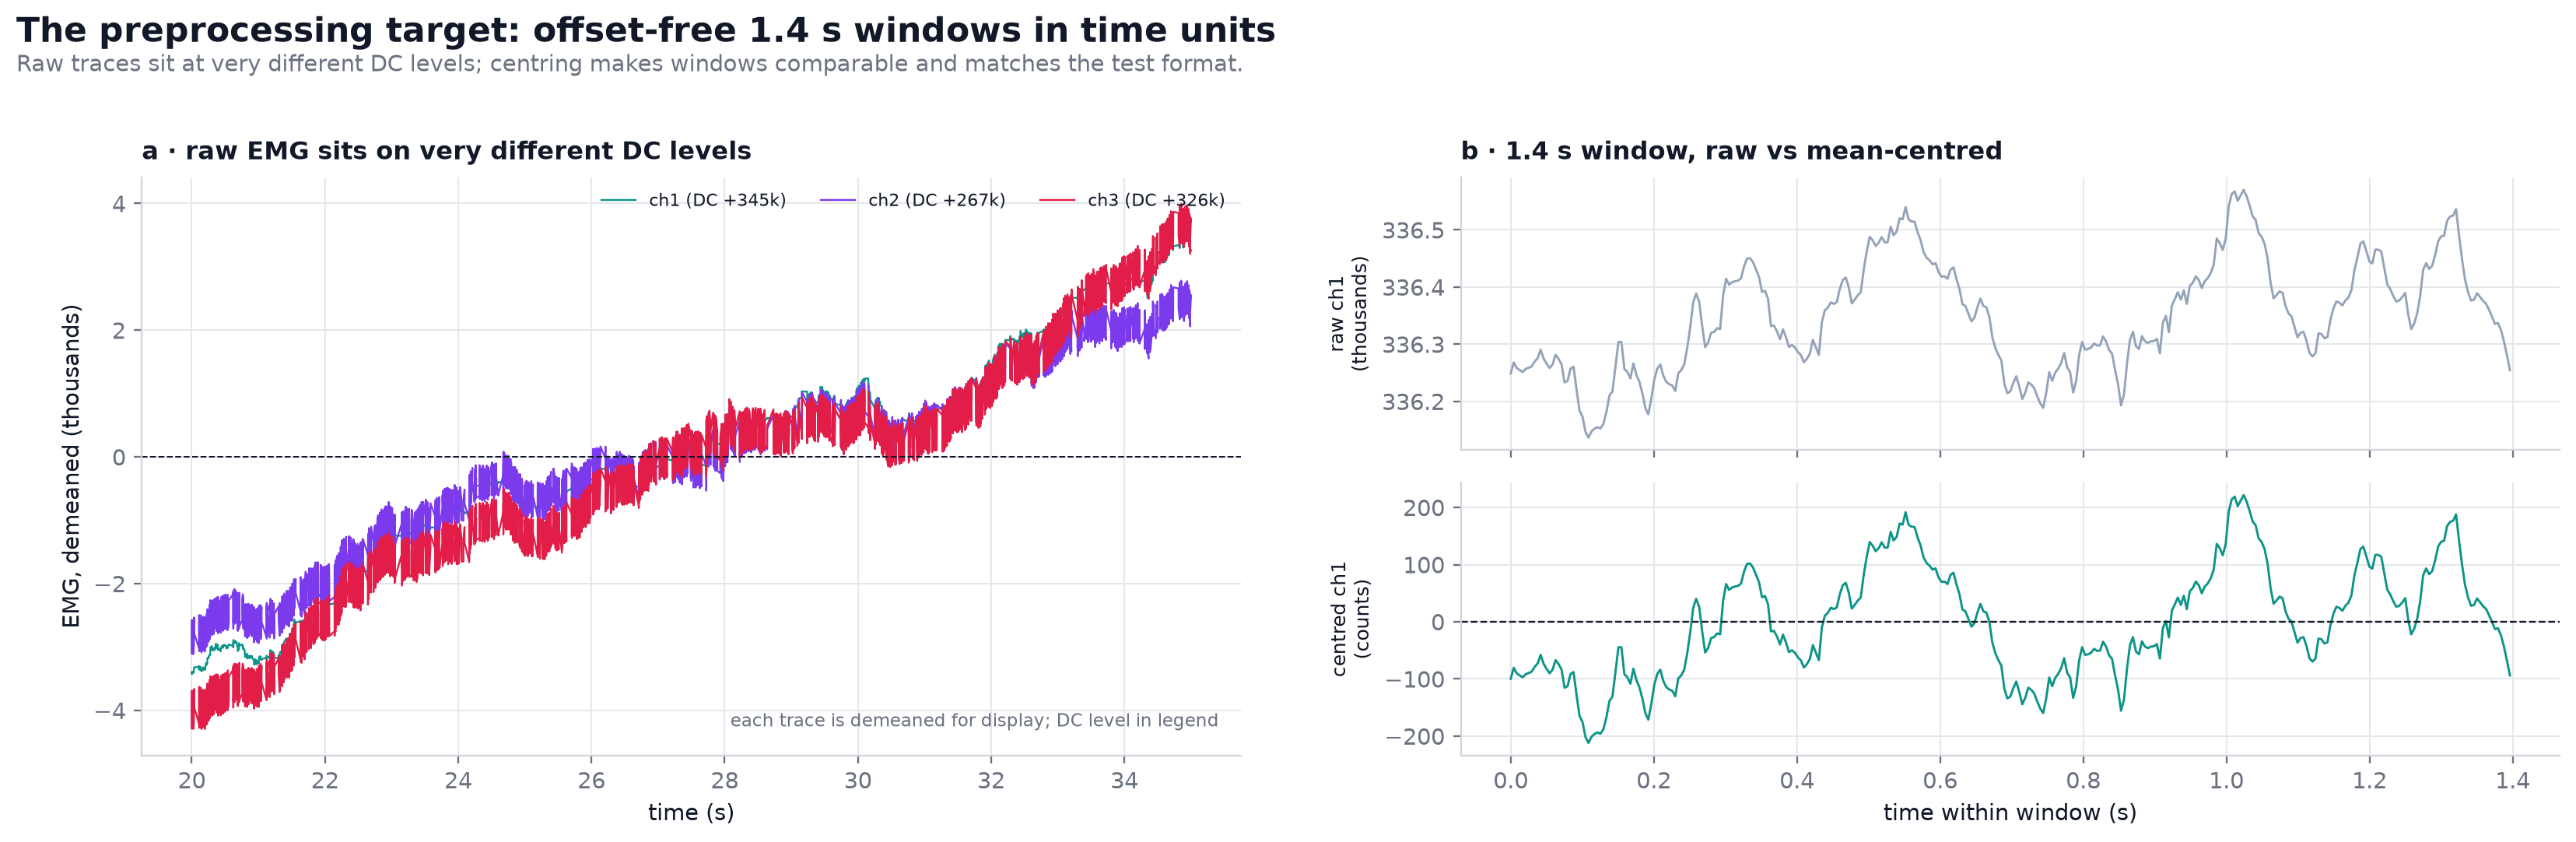

In [34]:
# ---- canonical windowing (already used above) ---------------------------------
demo = windows.sample(3, random_state=7)
print("Example windows:")
display(demo[["file", "label", "W", "rate", "t_start"]].round(2))

# row coverage
covered = set()
for w in windows.itertuples():
    covered.update((w.file, r) for r in range(w.start, w.start + w.W))
guided_rows = int((train.label_source == "guided").sum())
print(f"\nunique guided rows covered: {len(covered):,} / {guided_rows:,} "
      f"({len(covered)/guided_rows:.1%})")

fig = plt.figure(figsize=(16, 5.2))
gs = fig.add_gridspec(1, 2, wspace=0.2)
ax0 = fig.add_subplot(gs[0, 0])

# (a) same snippet, demeaned for display; the DC level is printed in the legend
d = train[train.file == "train_2"].sort_values("row")
sl = d[(d.t >= 20) & (d.t <= 35)]
dc = {c: sl[c].median() / 1000 for c in ["ch1", "ch2", "ch3"]}
for i, c in enumerate(["ch1", "ch2", "ch3"]):
    ax0.plot(sl.t, sl[c] / 1000 - dc[c], lw=0.8,
             color=["#0d9488", "#7c3aed", "#e11d48"][i],
             label=f"{c} (DC {dc[c]:+.0f}k)")
ax0.axhline(0, color=INK, lw=0.7, ls="--")
ax0.set_xlabel("time (s)")
ax0.set_ylabel("EMG, demeaned (thousands)")
ax0.legend(ncol=3, fontsize=7.5, loc="upper right")
ax0.text(0.98, 0.05, "each trace is demeaned for display; DC level in legend",
         transform=ax0.transAxes, ha="right", fontsize=8, color=MUTED)
panel_title(ax0, "a · raw EMG sits on very different DC levels")

# (b) one window, raw (top) and centred (bottom) — separate scales so shape is visible
w = windows[(windows.file == "train_2") & (windows.label == "fist")].iloc[0]
x = arrays[w.file][w.start:w.start + w.W]
tt = np.arange(w.W) / w.rate
gsb = gs[0, 1].subgridspec(2, 1, hspace=0.12)
axb1 = fig.add_subplot(gsb[0])
axb2 = fig.add_subplot(gsb[1], sharex=axb1)
axb1.plot(tt, x[:, 0] / 1000, color="#94a3b8", lw=1)
axb1.set_ylabel("raw ch1\n(thousands)", fontsize=8.5)
axb1.tick_params(labelbottom=False)
axb1.set_title("b · 1.4 s window, raw vs mean-centred", loc="left",
               fontsize=11, fontweight="bold", pad=8)
axb2.plot(tt, x[:, 0] - x[:, 0].mean(), color="#0d9488", lw=1)
axb2.axhline(0, color=INK, lw=0.8, ls="--")
axb2.set_xlabel("time within window (s)")
axb2.set_ylabel("centred ch1\n(counts)", fontsize=8.5)

fig.suptitle("The preprocessing target: offset-free 1.4 s windows in time units",
             x=0.012, y=0.99, ha="left", fontsize=15, fontweight="bold")
fig.text(0.012, 0.925, "Raw traces sit at very different DC levels; centring makes windows "
         "comparable and matches the test format.", fontsize=10, color=MUTED, ha="left")
fig.subplots_adjust(left=0.06, right=0.985, bottom=0.12, top=0.80, wspace=0.2)
savefig(fig, "15_preprocessing")

### 9.1 · The recipe, step by step

1. **Filter to `label_source == "guided"`.** Ignore `optical` and `none` rows for
   supervised training. If using optical rows at all, treat them as unlabelled.
2. **Split each session into contiguous segments.** Break on label change, on
   non-consecutive row indices (unlabelled/optical rows in between), and on time gaps
   > 0.3 s. Never let a window cross a segment boundary.
3. **Compute the session's effective rate** (`rows / duration`) and express 1.4 s in
   rows. Do not assume 230 Hz.
4. **Extract 1.4 s windows** with ~50% stride. Discard partial windows rather than pad.
   Optionally trim 100–150 ms at both ends to avoid transition transients (the first
   window's RMS is typically ≈1.0× the block median, mean 1.05×, but worst outliers reach
   ≈5×).
5. **Mean-centre every channel within every window** — exactly as the test set does.
   This removes DC offset and gravity.
6. **Normalise scale per window or per session.** For amplitude-based models:
   z-score each channel within the window, or divide by the window's channel-mean RMS.
   For test files, per-file normalisation is legitimate (no labels needed) and recovers
   the session-level scale that per-window z-scoring destroys.
7. **Resample each window to a fixed length** (e.g. 256 samples) for deep models.
   Never zero-pad short actions; resample so 120-row and 378-row actions carry equal
   temporal weight.
8. **Notch 50 Hz** (and 100 Hz if visible) before spectral feature extraction. Compute
   spectra with the *session's* true rate, then use Hz-based features only.
9. **Validate with `GroupKFold` on `file`.** Report macro-F1 with a session-level
   bootstrap CI. A random-window split is not a valid estimate of leaderboard
   performance.
10. **Drop or mask `train_13` ch1** (93% saturated) and `train_17` ch1 (15%). Consider
    dropping `train_16`'s post-gap region or treating the 22 s gap as a session break.

### 9.2 · What was deliberately *not* used

| Column(s) | Why not |
|---|---|
| `optical_class`, `optical_conf`, `optical_present`, `optical_score` | camera predictions; not in test; label-like |
| `roll`, `pitch`, `yaw` | orientation metadata; not in test |
| `thumb_curl` … `thumb_up` | hand-tracking / label-derived; not in test |
| `emg_new`, `imu_new`, `optical_new` | arrival flags, not signals |
| `handedness` | noisy metadata (97% Right) |
| `label_source` | annotation provenance, not a sensor input |

## 10 · Key takeaways

| # | Observation | Consequence |
|---|---|---|
| 1 | 28 sessions, 1.11 M rows, no participant ID | treat `file` as the CV group |
| 2 | timestamps are 1 ms-quantised and repeated | window by row count, never by `t` |
| 3 | effective rate 163–240 Hz (train), 90–280 Hz (test actions) | resample / use time-based features |
| 4 | test actions have 120–378 rows | resize, do not pad |
| 5 | 83% guided / 10% optical / 7% unlabelled | train on guided only |
| 6 | optical labels are a near-constant "open" detector | never use them as ground truth |
| 7 | rest = 24% of windows, gestures ~15% | class-balanced objective |
| 8 | DC offsets span ~0–630k; gains span 1000× | per-window centring + per-session scaling |
| 9 | ch1 saturated in `train_13` (93%) and `train_17` (15%) | drop/mask ch1 for those sessions |
| 10 | gaps up to 22.4 s | split windows at gaps |
| 11 | 50 Hz mains ridge; centroid 3–43 Hz across sessions | notch + per-session spectral normalisation |
| 12 | PC1 of channel RMS = 84%; channel profiles flat | channels are redundant; use temporal structure |
| 13 | fist is ~1.4× session-median loudness; rest ~0.9× | amplitude helps, but cannot separate rest |
| 14 | IMU gravity encodes placement | centre IMU per window |
| 15 | session-ID accuracy 89%; random CV +0.11 F1 | grouped validation only |
| 16 | simple baseline 0.34 macro-F1 [0.295, 0.382] | floor, not a target |

## 11 · Statistical validity notes

* **Unit of analysis.** Windows overlap by 50% and come from 28 sessions; treating them
  as independent samples would pseudo-replicate the data and shrink p-values
  artificially. All hypothesis tests in this notebook use **one summary per session**
  (n = 28). The machine-learning evaluation uses **5-fold `GroupKFold` by session**.
* **Non-parametric choices.** EMG features are skewed and heteroscedastic; we use
  Friedman (repeated-measures ranks), Wilcoxon signed-rank (paired), and permutation
  tests (difference of medians) rather than t-tests/ANOVA.
* **Effect sizes.** p-values are reported with Kendall's W, median ratios, and Cramér's
  V so that statistical significance is not confused with practical importance.
* **Multiple comparisons.** The train/test section tests three features; the Bonferroni
  threshold is 0.017. The smallest permutation p (spectral centroid, 0.108) is therefore
  reported as *not robust* — none of the three tests is significant.
* **Low power.** Five test files give very little power for distribution comparisons;
  absence of a significant difference is not evidence of similarity.
* **Camera agreement** is reported at the row level, where autocorrelation makes the
  interval optimistic. It is used descriptively (the effect is enormous), not as a formal
  test.
* **Bootstrap.** The macro-F1 interval resamples **sessions**, not windows, preserving
  within-session dependence.

## 12 · Limitations

* **No participant metadata.** We cannot verify whether two files share a participant.
  Grouping by file is conservative only if files are participants; if a participant
  appears in several files, even grouped CV overestimates generalisation.
* **Test labels are unavailable.** Class balance, action difficulty, and true
  cross-person shift cannot be measured.
* **No units.** EMG is in ADC counts with unknown gain; all amplitude conclusions are
  relative.
* **One-pass analysis.** Session-level normalisation is estimated from all windows in a
  session. At test time this is legal (no labels) but must be implemented identically.
* **Baseline only.** The 0.34 macro-F1 is not a competitive score; it validates the
  pipeline and quantifies difficulty.